# scRNA-seq preprocessing in Seurat: from count matrix to scaled data

**PBMC 10k tutorial, stage 1**: ambient RNA check, doublet detection, quality control, filtering, normalization, highly variable genes and scaling

This notebook covers everything that happens **between the Cell Ranger count matrix and the first PCA**. These steps decide which barcodes are treated as cells and which genes carry signal. They also remove technical variation, so that what remains is mostly biology. Every downstream result (clusters, cell types, differential expression) inherits the decisions made here.

### Learning objectives

By the end of the session you should be able to:

1. Describe how a droplet-based (10x Genomics) count matrix is structured, and why it is sparse.
2. Explain where **ambient RNA** comes from, how it contaminates every cell, and how `SoupX` estimates and removes it (here the contamination is estimated; the correction is shown as commands for a full analysis).
3. Explain how **doublets** arise, why only some of them can be detected computationally, and how `scDblFinder` works.
4. Compute and interpret the standard **QC metrics**: library size, detected genes, mitochondrial / ribosomal / haemoglobin fractions and library complexity.
5. Choose **filtering thresholds** from the data (median absolute deviations) rather than from rules of thumb, and recognise when QC could remove real biology.
6. Explain why counts must be **normalized**, what `LogNormalize` does mathematically, and how it changes the mean–variance relationship.
7. Explain how **highly variable genes** are selected (the `vst` method) and why feature selection is needed.
8. Explain what **scaling** (z-scoring) does, why it precedes PCA, and the risks of regressing out covariates.

### Workflow

| Step | Question it answers | Seurat function | Scanpy equivalent |
|---|---|---|---|
| 1. Load data | What did the sequencer measure? | `Read10X`, `CreateSeuratObject` | `sc.read_10x_mtx` |
| 2. Ambient RNA | How much of each cell's counts come from free-floating RNA? | `SoupX::SoupChannel`, `calculateContaminationFraction` (check only; `adjustCounts` in a full analysis) | no Scanpy built-in (SoupX via rpy2, CellBender, scAR) |
| 3. Doublets | Which barcodes contain two cells? | `scDblFinder::scDblFinder` | `sc.pp.scrublet` |
| 4. QC metrics | Which barcodes look like healthy, intact single cells? | `PercentageFeatureSet` | `sc.pp.calculate_qc_metrics` |
| 5. Filtering thresholds | Where do we draw the line? | median absolute deviation (MAD) outliers | `scanpy` + MAD outliers |
| 6. Apply filters | Which cells and genes go forward? | `subset` | boolean indexing, `sc.pp.filter_genes` |
| 7. Normalization | How do we compare cells sequenced to different depths? | `NormalizeData` | `sc.pp.normalize_total` + `sc.pp.log1p` |
| 8. Highly variable genes | Which genes carry biological signal? | `FindVariableFeatures` | `sc.pp.highly_variable_genes` |
| 9. Scaling | How do we give each gene equal weight before PCA? | `ScaleData` | `sc.pp.scale` |

**Why ambient RNA and doublets come first.** Both change the counts of a barcode, and both are best handled on the full set of Cell Ranger barcodes. In a full analysis SoupX corrects the counts of every cell first, so the doublet scores and every QC metric are computed on the corrected counts. In this tutorial Section 2 only **measures** the contamination (the correction is too slow without clusters for a live session), and all later steps use the uncorrected counts. scDblFinder sets its expected doublet rate from the number of cells it is given, so it runs before any cell is removed. Cells are only flagged in Sections 3–5 and are removed together in Section 6. Section 10 shows how long each stage took.

**Not covered here** (later sessions or beyond scope): dimensionality reduction, clustering and annotation; ambient RNA **correction** (`SoupX::adjustCounts`; Section 2 estimates the contamination and lists the commands for a full run); cell-cycle scoring; integration of several samples.

### Glossary

| Term | Meaning |
|---|---|
| **Barcode** | A 16-nt cell barcode that labels every cDNA molecule from one droplet. One barcode ideally = one cell. |
| **UMI** | Unique Molecular Identifier: a random 12-nt tag on each captured mRNA molecule. Reads with the same UMI and gene are PCR copies, so counting UMIs counts *molecules*, not reads. |
| **Feature** | A gene (or antibody / guide in multimodal data). |
| **Count matrix** | Genes × barcodes table of UMI counts. |
| **Library size** (`nCount_RNA`) | Total UMIs in a barcode. It reflects RNA content, capture efficiency and sequencing depth. |
| **Detected genes** (`nFeature_RNA`) | Number of genes with at least one UMI in a barcode. |
| **Ambient RNA ("soup")** | Cell-free mRNA in the cell suspension, released by lysed or dying cells. Every droplet captures some of it along with its cell. |
| **Contamination fraction (ρ)** | The share of a cell's UMIs that come from the soup rather than from the cell itself. |
| **Doublet** | A droplet that captured two (or more) cells, so one barcode reports a mixture. |
| **Size factor** | A per-cell scaling factor used to remove differences in library size. |

### Dataset

A 10x Genomics peripheral blood mononuclear cell (PBMC) dataset with roughly 10,000 cells: the Cell Ranger 4.0 *filtered* feature-barcode matrix, gene expression only, human GRCh38 (2020-A) annotation with 36,601 genes. PBMCs are a standard benchmark because their cell types are well characterised: T, NK, B cells, monocytes, dendritic cells and platelets.

**Input:** `data/pbmc10_data/` (`barcodes.tsv.gz`, `features.tsv.gz`, `matrix.mtx.gz`). **Outputs:** `data/figures/pbmc10k_stage1/`, `data/tables/pbmc10k_stage1/` and `data/pbmc10k_stage1_preprocessed.rds`. All paths are relative to the project root (the folder with `install.sh`), and `data/` is git-ignored.

**Requirements:** run `bash install.sh` from the project root in WSL2. It creates the `seurat_env` conda environment (R 4.4.3, Seurat 5, SoupX, scDblFinder) and the Jupyter kernel.

**Optional:** only the *filtered* matrix is included. If you download Cell Ranger's `raw_feature_bc_matrix` (all droplets) for the same run into `data/pbmc10_raw/`, Section 2 measures the ambient RNA from real empty droplets instead of approximating it.

## 0. Setup

The first cell also starts a **stage timer** (`mark_stage()`); the runtime of every section is summarised at the end of Section 10.

In [1]:
suppressPackageStartupMessages({
  library(Seurat)
  library(Matrix)
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(patchwork)
})
# SoupX and scDblFinder are called with pkg:: later, so their many dependencies are not attached.

seed <- 198716                     # one seed for every random step -> reproducible results
set.seed(seed)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 120)   # inline plot size in Jupyter
theme_set(theme_classic(base_size = 12))

# ---- Runtime per stage ----
# mark_stage("name") is called at the start of each stage; the "Runtime per stage" block at the end turns the marks
# into a table. Wall-clock (elapsed) times are meaningful for an uninterrupted top-to-bottom run (Run All / nbconvert);
# CPU time excludes the time the kernel sat idle between cells (it can exceed elapsed time with a multithreaded BLAS).
stage_marks <- list()
mark_stage <- function(stage) {
  pt <- proc.time()
  stage_marks[[stage]] <<- list(time = as.numeric(Sys.time()), cpu = unname(pt[["user.self"]] + pt[["sys.self"]]))
  invisible(stage)
}
mark_stage("0. Setup")

c(R = as.character(getRversion()),
  Seurat = as.character(packageVersion("Seurat")),
  SeuratObject = as.character(packageVersion("SeuratObject")),
  SoupX = as.character(packageVersion("SoupX")),
  scDblFinder = as.character(packageVersion("scDblFinder")))

R       Seurat SeuratObject        SoupX  scDblFinder 
     "4.4.3"      "5.5.1"      "5.4.0"      "1.6.2"     "1.23.4"

In [2]:
# ---- All paths are relative to the project root: the folder that holds install.sh and scripts/ ----
# Jupyter starts in the notebook's own folder (scripts/seurat_analysis/), so look upwards from there for the root.
find_project_root <- function(start = getwd()) {
  dir <- normalizePath(start, winslash = "/", mustWork = TRUE)
  repeat {
    if (file.exists(file.path(dir, "install.sh")) && dir.exists(file.path(dir, "scripts"))) return(dir)
    parent <- dirname(dir)
    if (parent == dir) stop("Project root (folder with install.sh and scripts/) not found above ", start)
    dir <- parent
  }
}
base_dir    <- find_project_root()
data_dir    <- file.path(base_dir, "data", "pbmc10_data")          # 10x input (git-ignored)
results_dir <- file.path(base_dir, "data")                         # all results go here (git-ignored)
fig_dir     <- file.path(results_dir, "figures", "pbmc10k_stage1")
table_dir   <- file.path(results_dir, "tables",  "pbmc10k_stage1")
rds_file    <- file.path(results_dir, "pbmc10k_stage1_preprocessed.rds")

if (!dir.exists(data_dir)) stop("10x input folder not found: ", data_dir)
dir.create(fig_dir,   showWarnings = FALSE, recursive = TRUE)
dir.create(table_dir, showWarnings = FALSE, recursive = TRUE)

# Show a plot inline and save a copy in fig_dir
save_plot <- function(p, filename, width = 10, height = 6) {
  ggsave(file.path(fig_dir, filename), plot = p, width = width, height = height, dpi = 300, bg = "white")
  p
}

# Keep a record of how many cells and genes survive each step
qc_log <- data.frame(step = character(), cells = integer(), genes = integer())
log_step <- function(step, cells, genes) {
  qc_log <<- rbind(qc_log, data.frame(step = step, cells = cells, genes = genes))
  qc_log
}

cat("Project root:", base_dir, "\n")

Project root: /mnt/e/DeCodeLife_scRNAseq 


## 1. The count matrix

Cell Ranger aligns reads to the genome, collapses PCR duplicates by UMI, and writes a **genes × barcodes matrix of UMI counts**. The *filtered* matrix keeps only the barcodes that Cell Ranger's cell-calling algorithm judged to contain a cell; the *raw* matrix contains every barcode, including hundreds of thousands of empty droplets.

The matrix is stored in the sparse **Matrix Market** format (`matrix.mtx.gz`), which lists only non-zero entries as (gene, barcode, count) triplets. `features.tsv.gz` holds the Ensembl ID, gene symbol and feature type of each row, and `barcodes.tsv.gz` holds the cell barcode of each column.

Why sparse? A typical cell has 10<sup>3</sup>–10<sup>5</sup> mRNA molecules, and 10x captures roughly 10–50% of them. So in any one cell most of the ~36,000 annotated genes are never observed. Svensson (2020) showed these zeros are largely what we expect from sampling a few thousand molecules per cell. They are **not** an excess of "dropouts" needing special models.

In [3]:
mark_stage("1. Load the count matrix")

# Scanpy: sc.read_10x_mtx(path, var_names='gene_symbols')
counts <- Read10X(data.dir = data_dir, gene.column = 2)      # gene symbols as row names (duplicates made unique)
if (is.list(counts)) counts <- counts[["Gene Expression"]]   # keep RNA only if other modalities exist

class(counts)
dim(counts)

[1] "dgCMatrix"
attr(,"package")
[1] "Matrix"

[1] 36601 10985

In [4]:
# How sparse is the matrix, and how much memory does sparsity save?
n_entries <- as.numeric(nrow(counts)) * ncol(counts)
n_nonzero <- Matrix::nnzero(counts)
data.frame(
  genes             = nrow(counts),
  barcodes          = ncol(counts),
  non_zero_entries  = n_nonzero,
  percent_zero      = round(100 * (1 - n_nonzero / n_entries), 2),
  dense_size_GB     = round(n_entries * 8 / 1e9, 2),                    # 8 bytes per double
  sparse_size_GB    = round(as.numeric(object.size(counts)) / 1e9, 3)
)

genes,barcodes,non_zero_entries,percent_zero,dense_size_GB,sparse_size_GB
<int>,<int>,<int>,<dbl>,<dbl>,<dbl>
36601,10985,28464924,92.92,3.22,0.345


In [5]:
# A small corner of the matrix: marker genes of T cells (CD3E), monocytes (LYZ), B cells (MS4A1), NK cells (GNLY), platelets (PPBP)
show_genes <- intersect(c("CD3E", "LYZ", "MS4A1", "GNLY", "PPBP"), rownames(counts))
counts[show_genes, 1:8]      # "." = 0 in sparse notation

5 x 8 sparse Matrix of class "dgCMatrix"
      AAACCCAGTATATGGA-1 AAACCCAGTATCGTAC-1 AAACCCAGTCGGTGAA-1
CD3E                   1                  .                  3
LYZ                    1                 14                  1
MS4A1                  .                  .                  .
GNLY                   .                  .                 14
PPBP                   .                  .                  .
      AAACCCAGTTAGAAAC-1 AAACCCAGTTATCTTC-1 AAACCCAGTTGCCGAC-1
CD3E                   1                  .                  .
LYZ                  347                  .                 81
MS4A1                  .                  .                  .
GNLY                   .                 31                  .
PPBP                   .                  .                  .
      AAACCCAGTTTCCCAC-1 AAACCCATCAGACAAA-1
CD3E                   4                  2
LYZ                  187                  .
MS4A1                  .                  .
GNLY                   .   

**Most non-zero counts are 1 or 2.** The data are small integers, not continuous intensities. This is why scRNA-seq needs count-based statistics (Poisson / negative binomial) and careful transformation before methods that assume roughly normal data, such as PCA.

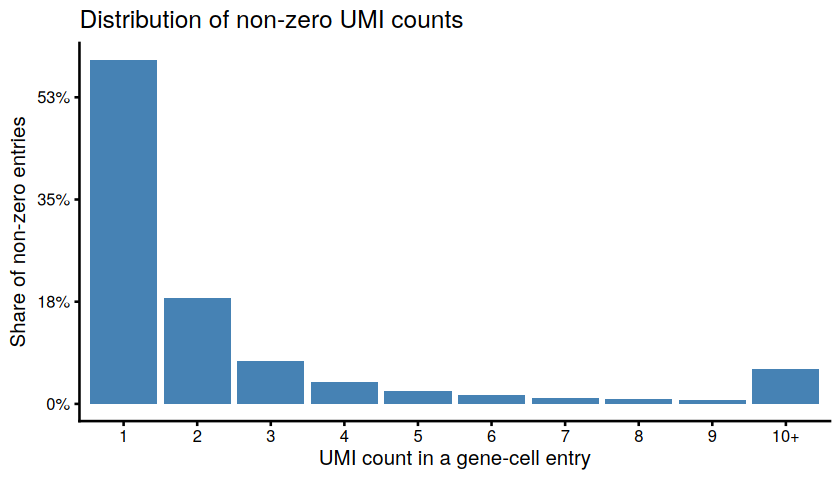

In [6]:
nz_values <- data.frame(count = pmin(counts@x, 10))       # counts@x = the non-zero values of a dgCMatrix
nz_values$count <- factor(ifelse(nz_values$count >= 10, "10+", as.character(nz_values$count)),
                          levels = c(as.character(1:9), "10+"))

options(repr.plot.width = 7, repr.plot.height = 4)
p <- ggplot(nz_values, aes(x = count)) +
  geom_bar(fill = "steelblue") +
  scale_y_continuous(labels = scales::label_percent(scale = 100 / nrow(nz_values))) +
  labs(title = "Distribution of non-zero UMI counts", x = "UMI count in a gene-cell entry", y = "Share of non-zero entries")
save_plot(p, "01_nonzero_count_distribution.png", width = 7, height = 4)

### Barcode-rank plot

Sorting barcodes by total UMIs and plotting on log–log axes gives the **barcode-rank ("knee") plot**. In the *raw* matrix it shows a plateau of real cells, a sharp drop (the knee), and a long tail of empty droplets that contain only ambient RNA. Here we only have the *filtered* matrix, so we see the cell plateau plus the start of the drop: the barcodes Cell Ranger kept just above the knee. Barcodes at the low end are the ones most likely to be empty or damaged. The empty droplets of the raw matrix are also what SoupX uses to measure the ambient RNA (Section 2); here they are missing.

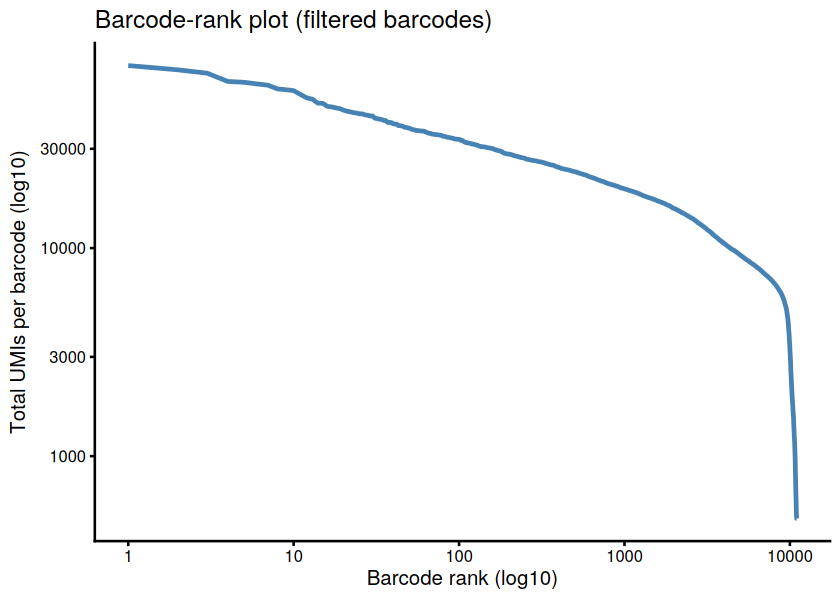

In [7]:
barcode_rank <- data.frame(umi = sort(Matrix::colSums(counts), decreasing = TRUE))
barcode_rank$rank <- seq_len(nrow(barcode_rank))

options(repr.plot.width = 7, repr.plot.height = 5)
p <- ggplot(barcode_rank, aes(x = rank, y = umi)) +
  geom_line(linewidth = 1, colour = "steelblue") +
  scale_x_log10() + scale_y_log10() +
  labs(title = "Barcode-rank plot (filtered barcodes)", x = "Barcode rank (log10)", y = "Total UMIs per barcode (log10)")
save_plot(p, "02_barcode_rank_plot.png", width = 7, height = 5)

genes_never_detected           genes_in_fewer_than_3_cells 
                                10540                                 13740 
genes_in_at_least_10_percent_of_cells 
                                 7472

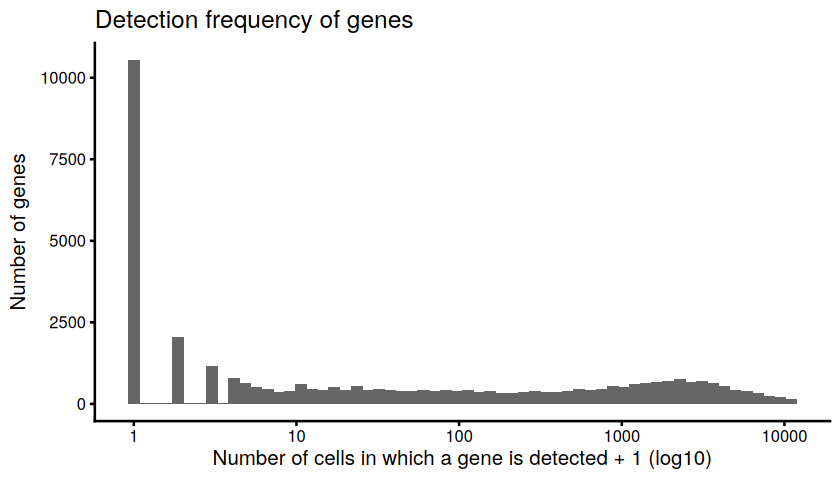

In [8]:
# Gene-level view: in how many cells is each gene detected?
cells_per_gene <- Matrix::rowSums(counts > 0)
c(genes_never_detected = sum(cells_per_gene == 0),
  genes_in_fewer_than_3_cells = sum(cells_per_gene < 3),
  genes_in_at_least_10_percent_of_cells = sum(cells_per_gene >= 0.1 * ncol(counts)))

options(repr.plot.width = 7, repr.plot.height = 4)
p <- ggplot(data.frame(cells = cells_per_gene + 1), aes(x = cells)) +
  geom_histogram(bins = 60, fill = "grey40") +
  scale_x_log10() +
  labs(title = "Detection frequency of genes", x = "Number of cells in which a gene is detected + 1 (log10)", y = "Number of genes")
save_plot(p, "03_gene_detection_histogram.png", width = 7, height = 4)

### The Seurat object

`CreateSeuratObject` wraps the matrix with per-cell metadata (`meta.data`). Seurat 5 stores the expression data of an assay in **layers**:

| Layer | Content | Created by |
|---|---|---|
| `counts` | raw UMI counts | `CreateSeuratObject` |
| `data` | normalized, log-transformed values | `NormalizeData` |
| `scale.data` | per-gene z-scores (HVGs only) | `ScaleData` |

`nCount_RNA` (library size) and `nFeature_RNA` (detected genes) are computed automatically. No cells or genes are removed at this point (`min.cells = 0`, `min.features = 0`), so we can see the full distributions before deciding on filters.

In [9]:
pbmc <- CreateSeuratObject(counts = counts, project = "pbmc10k", min.cells = 0, min.features = 0)
rm(counts, nz_values)

pbmc
Layers(pbmc[["RNA"]])
head(pbmc@meta.data)
log_step("1. Cell Ranger filtered barcodes", ncol(pbmc), nrow(pbmc))

An object of class Seurat 
36601 features across 10985 samples within 1 assay 
Active assay: RNA (36601 features, 0 variable features)
 1 layer present: counts

[1] "counts"

,orig.ident,nCount_RNA,nFeature_RNA
,<fct>,<dbl>,<int>
AAACCCAGTATATGGA-1,pbmc10k,887,344
AAACCCAGTATCGTAC-1,pbmc10k,1628,749
AAACCCAGTCGGTGAA-1,pbmc10k,6591,1868
AAACCCAGTTAGAAAC-1,pbmc10k,17318,3809
AAACCCAGTTATCTTC-1,pbmc10k,3527,1517
AAACCCAGTTGCCGAC-1,pbmc10k,6228,2110


step,cells,genes
<chr>,<dbl>,<dbl>
1. Cell Ranger filtered barcodes,10985,36601


## 2. Ambient RNA: a quick SoupX check (no correction in this tutorial)

### Where ambient RNA comes from

During dissociation and handling some cells lyse, and their mRNA floats freely in the suspension. Every droplet captures a little of this **ambient RNA ("soup")** together with its cell, and the soup molecules receive the droplet's cell barcode. The observed counts of a cell are therefore a mixture:

$$\text{observed}_{g,c} \;=\; \text{endogenous}_{g,c} \;+\; \rho_c \, N_c \, s_g$$

where $N_c$ is the cell's total UMI count, $\rho_c$ the **contamination fraction** (share of the cell's UMIs that come from the soup) and $s_g$ the **soup profile** (share of gene *g* in the soup). The soup resembles a bulk RNA sample of the lysed cells. It is dominated by very highly expressed genes of abundant or fragile cell types: in PBMCs, monocyte genes (*LYZ*, *S100A8*, *S100A9*), platelet genes (*PPBP*, *PF4*), immunoglobulins from B and plasma cells, and haemoglobins from residual red blood cells.

**Why it matters.** Soup adds marker genes to cells that do not express them, e.g. *LYZ* in T cells or *IGKC* in monocytes. This blurs cluster boundaries, creates spurious differential expression, and makes clean singlets co-express markers of two lineages, so they look like heterotypic doublets.

### How SoupX works (Young & Behjati, 2020)

1. **Soup profile $s_g$**: from the *empty droplets* of the raw Cell Ranger matrix (barcodes with very few UMIs, which contain only soup).
2. **Contamination fraction ρ**: from genes that are certainly **not expressed** in some cells. Immunoglobulins are made only by B / plasma cells and haemoglobins only by erythrocytes. In any other cell, every count of these genes must come from the soup, so $\rho = \text{observed} / (N_c \, s_g)$ summed over those cells. `estimateNonExpressingCells` excludes the cells that clearly do express a gene set. (`autoEstCont` automates the gene choice but needs clusters, which come in the next session.)
3. **Correction**: `adjustCounts` subtracts the expected soup counts $\rho N_c s_g$ from each cell, removing the genes most likely to be soup first, and returns **integer** counts.

### What is different in this notebook

* **No empty droplets:** we only have the *filtered* matrix (Section 1). The soup profile is approximated by the **pooled expression of all cells**. This assumes the lysed cells resemble the captured cells; it underestimates the soup share of fragile cell types that lysed before capture. If `data/pbmc10_raw/` exists (Cell Ranger `raw_feature_bc_matrix`), the code below uses real empty droplets instead.
* **No clusters:** every cell is treated as its own group (`clusters = FALSE`). This is less robust than per-cluster estimation, so ρ should be checked again after clustering.
* **Check only, no correction.** We estimate the soup profile and ρ, which takes seconds, but do **not** run `adjustCounts`. Without clusters it builds a dense genes × cells matrix one cell at a time, which is too slow for a live session. All later sections use the **uncorrected** counts, so keep the soup genes in mind when reading the doublet and HVG results.

### Full analysis: include the correction

A full analysis should correct the counts **before** doublet detection and QC (Sections 3–4), then run the rest of this notebook on the corrected counts.

**With the Cell Ranger output folder** (`outs/`, which contains `raw_feature_bc_matrix/`, `filtered_feature_bc_matrix/` and Cell Ranger's clustering in `analysis/`), the standard SoupX run is:

```r
sc        <- SoupX::load10X("path/to/cellranger/outs")    # soup from empty droplets + Cell Ranger clusters
sc        <- SoupX::autoEstCont(sc)                         # estimates rho automatically
corrected <- SoupX::adjustCounts(sc, roundToInt = TRUE)     # integer, ambient-corrected counts
pbmc      <- CreateSeuratObject(counts = corrected, project = "pbmc10k", min.cells = 0, min.features = 0)
# ... then continue with Section 3 (doublets) and Section 4 (QC metrics)
```

**With only a filtered matrix** (as here), cluster first (next session), give SoupX the clusters, which also makes `adjustCounts` fast, then re-run this notebook from Section 3 on the corrected counts:

```r
# sc: the SoupChannel from the cells below (soup profile + rho)
sc        <- SoupX::setClusters(sc, setNames(as.character(pbmc$seurat_clusters), colnames(pbmc)))
corrected <- SoupX::adjustCounts(sc, roundToInt = TRUE)
pbmc[["RNA_raw"]] <- CreateAssay5Object(counts = LayerData(pbmc, assay = "RNA", layer = "counts"))   # keep the raw counts
LayerData(pbmc, assay = "RNA", layer = "counts") <- corrected
pbmc$nCount_RNA   <- Matrix::colSums(corrected)
pbmc$nFeature_RNA <- Matrix::colSums(corrected > 0)
```

In [10]:
mark_stage("2. Ambient RNA check (SoupX)")

counts_cells <- LayerData(pbmc, assay = "RNA", layer = "counts")        # table of counts (toc): the called cells

# Optional: Cell Ranger raw_feature_bc_matrix (all droplets) for a soup profile from real empty droplets
raw_droplets_dir <- file.path(base_dir, "data", "pbmc10_raw")
if (dir.exists(raw_droplets_dir)) {
  tod <- Read10X(data.dir = raw_droplets_dir, gene.column = 2)          # table of droplets (tod)
  if (is.list(tod)) tod <- tod[["Gene Expression"]]
  sc <- SoupX::SoupChannel(tod = tod[rownames(counts_cells), ], toc = counts_cells)   # soup = droplets with < 100 UMIs
  soup_source <- "empty droplets of the raw matrix"
  rm(tod)
} else {
  # No empty droplets: approximate the soup by the pooled expression of all cells
  sc <- SoupX::SoupChannel(tod = counts_cells, toc = counts_cells, calcSoupProfile = FALSE)
  sc <- SoupX::setSoupProfile(sc, data.frame(est    = Matrix::rowSums(counts_cells) / sum(counts_cells),
                                             counts = Matrix::rowSums(counts_cells),
                                             row.names = rownames(counts_cells)))
  soup_source <- "pooled expression of all cells (no raw matrix)"
}
cat("Soup profile estimated from:", soup_source, "\n")

# The genes that dominate the soup (est = share of all soup UMIs)
soup_top <- head(sc$soupProfile[order(sc$soupProfile$est, decreasing = TRUE), ], 20)
soup_top$percent_of_soup <- round(100 * soup_top$est, 2)
soup_top[, c("counts", "percent_of_soup")]

Soup profile estimated from: pooled expression of all cells (no raw matrix) 


,counts,percent_of_soup
,<dbl>,<dbl>
MALAT1,3796855,3.31
MT-CO1,1765110,1.54
B2M,1377292,1.20
MT-CO2,1186083,1.03
EEF1A1,1148249,1.00
MT-CO3,1074107,0.94
MT-ATP6,988460,0.86
TMSB4X,939882,0.82
RPL41,895392,0.78


In [11]:
# Gene sets that are expressed by only a few cell types (as in the SoupX PBMC vignette).
# In all other cells their counts can only come from the soup, which gives the contamination fraction rho.
soup_gene_sets <- list(
  immunoglobulin = c("IGHA1", "IGHA2", "IGHG1", "IGHG2", "IGHG3", "IGHG4", "IGHD", "IGHE", "IGHM",
                     "IGLC1", "IGLC2", "IGLC3", "IGLC5", "IGLC6", "IGLC7", "IGKC"),
  haemoglobin    = c("HBB", "HBA1", "HBA2")
)
soup_gene_sets <- lapply(soup_gene_sets, intersect, rownames(pbmc))

# Which cells can be used for each set? (FALSE = the cell clearly expresses the set itself, e.g. B cells for Ig)
use_to_est <- SoupX::estimateNonExpressingCells(sc, nonExpressedGeneList = soup_gene_sets, clusters = FALSE)
colSums(use_to_est)

rho_fallback <- 0.05                      # used only if rho cannot be estimated
sc <- tryCatch(
  SoupX::calculateContaminationFraction(sc, soup_gene_sets, useToEst = use_to_est, verbose = FALSE),
  error = function(e) {
    message("rho could not be estimated (", conditionMessage(e), "); using ", rho_fallback)
    SoupX::setContaminationFraction(sc, rho_fallback)
  })
rho <- sc$metaData$rho[1]
c(contamination_fraction_rho = round(rho, 4), percent = round(100 * rho, 2))

No clusters found or supplied, using every cell as its own cluster.



immunoglobulin    haemoglobin 
         10043          10957

contamination_fraction_rho                    percent 
                    0.0361                     3.6100

In [12]:
# What would the correction remove? Nothing is changed here: the counts stay uncorrected.
# Expected soup UMIs in a cell = rho x library size; for one gene, additionally x the gene's share of the soup.
soup_umis_expected <- rho * pbmc$nCount_RNA
summary(soup_umis_expected)

soup_markers <- intersect(c("LYZ", "S100A9", "S100A8", "PPBP", "IGKC", "HBB", "CD3E", "MS4A1"), rownames(pbmc))
marker_soup <- data.frame(
  gene                      = soup_markers,
  percent_of_soup           = round(100 * sc$soupProfile[soup_markers, "est"], 3),
  soup_umis_in_median_cell  = round(rho * median(pbmc$nCount_RNA) * sc$soupProfile[soup_markers, "est"], 2),
  percent_cells_detecting   = round(100 * Matrix::rowMeans(counts_cells[soup_markers, ] > 0), 1)
)
write.csv(marker_soup, file.path(table_dir, "soupx_check_marker_genes.csv"), row.names = FALSE)
marker_soup

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   18.1   238.7   316.3   376.8   481.6  2716.7 

,gene,percent_of_soup,soup_umis_in_median_cell,percent_cells_detecting
,<chr>,<dbl>,<dbl>,<dbl>
LYZ,LYZ,0.645,2.04,67.7
S100A9,S100A9,0.661,2.09,67.3
S100A8,S100A8,0.474,1.50,55.9
PPBP,PPBP,0.001,0.00,1.2
IGKC,IGKC,0.284,0.90,36.8
HBB,HBB,0.000,0.00,0.1
CD3E,CD3E,0.030,0.09,51.8
MS4A1,MS4A1,0.010,0.03,11.6


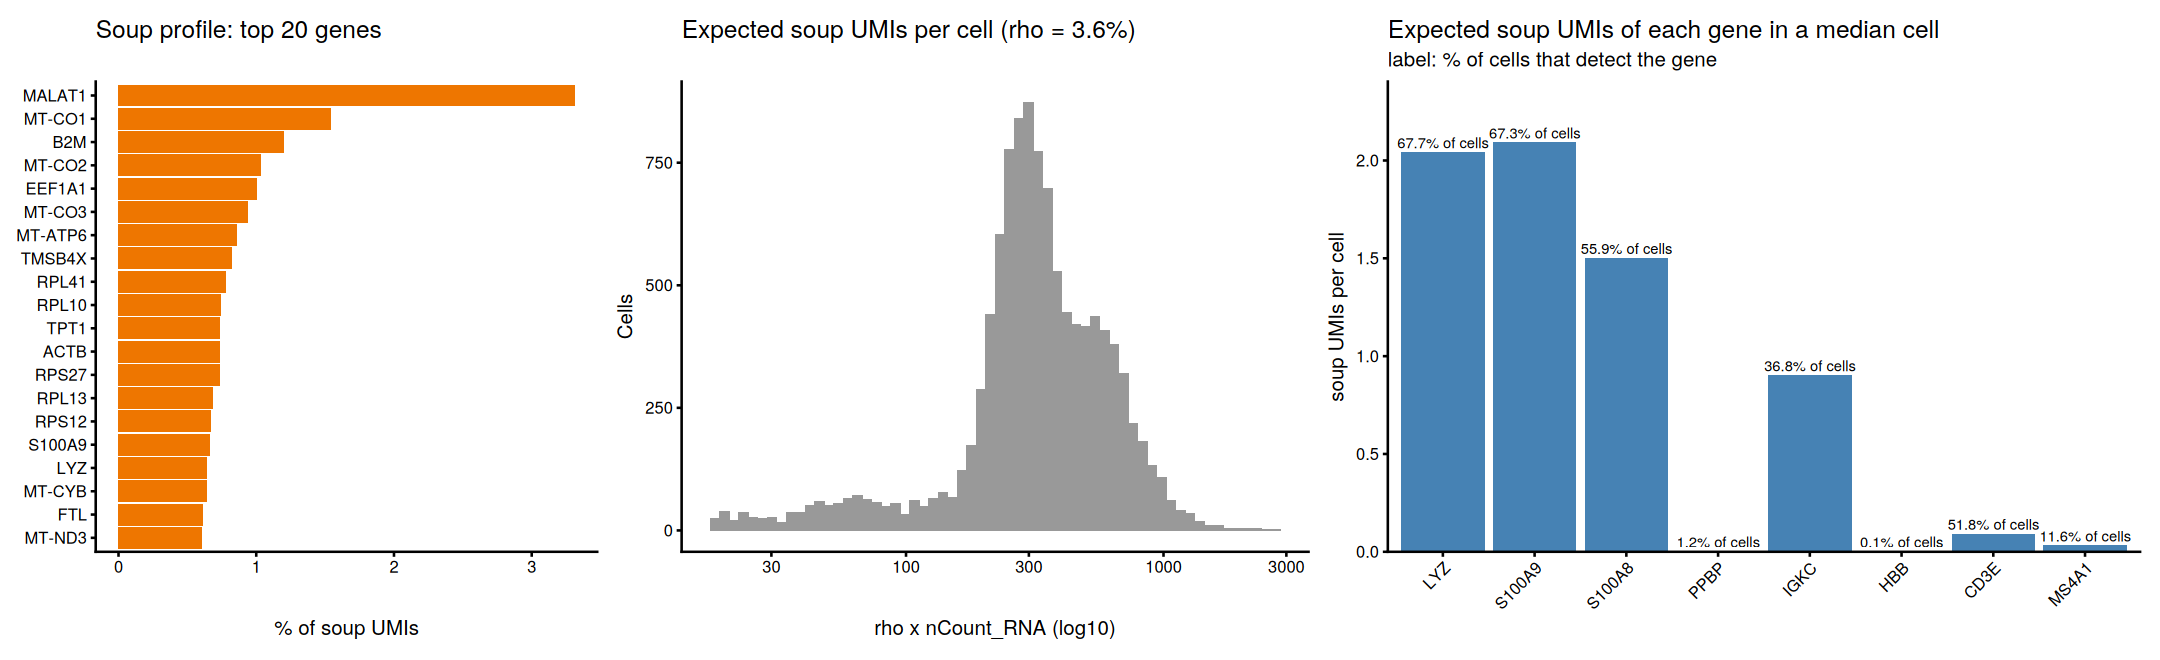

In [13]:
p1 <- ggplot(soup_top, aes(x = percent_of_soup, y = factor(rownames(soup_top), levels = rev(rownames(soup_top))))) +
  geom_col(fill = "darkorange2") +
  labs(title = "Soup profile: top 20 genes", x = "% of soup UMIs", y = NULL)
p2 <- ggplot(data.frame(soup = soup_umis_expected), aes(x = soup)) +
  geom_histogram(bins = 60, fill = "grey60") +
  scale_x_log10() +
  labs(title = sprintf("Expected soup UMIs per cell (rho = %.1f%%)", 100 * rho), x = "rho x nCount_RNA (log10)", y = "Cells")
p3 <- ggplot(marker_soup, aes(x = factor(gene, levels = soup_markers), y = soup_umis_in_median_cell)) +
  geom_col(fill = "steelblue") +
  geom_text(aes(label = paste0(percent_cells_detecting, "% of cells")), vjust = -0.4, size = 3) +
  scale_y_continuous(expand = expansion(mult = c(0, 0.15))) +
  labs(title = "Expected soup UMIs of each gene in a median cell", subtitle = "label: % of cells that detect the gene",
       x = NULL, y = "soup UMIs per cell") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

options(repr.plot.width = 18, repr.plot.height = 5.5)
p <- (p1 | p2 | p3) + plot_layout(widths = c(0.8, 1, 1.2))
save_plot(p, "06a_soupx_check.png", width = 18, height = 5.5)
rm(sc, counts_cells, use_to_est, soup_umis_expected)

**Reading the plots.** The soup profile should be dominated by highly expressed genes of abundant or fragile cells. A typical cell carries roughly ρ × its library size soup UMIs. For a soup-dominant gene such as *LYZ*, that can be enough for the gene to be **detected in cells that do not express it** (T, B and NK cells), which inflates its "% of cells detecting". Lineage markers with a small soup share, such as *CD3E* and *MS4A1*, are barely affected. Because the counts are **not corrected** in this tutorial, expect some co-detection of lineage markers in singlets (Section 3) and soup genes among the HVGs (Section 8).

> **Discussion**
> 1. Why can ρ not be estimated from a gene that every cell expresses, such as *ACTB*?
> 2. We approximated the soup by the pooled cells. Which cell types would be under-represented in this estimate, and how would that bias a correction?
> 3. What happens to a rare population if ρ is over-estimated and the counts are corrected? Which genes would it lose first?
> 4. Ambient RNA makes singlets co-express markers of two lineages. Why does that matter for the next step, doublet detection?

## 3. Doublet detection

### How doublets arise

Cells are loaded into droplets at random, so the number of cells per droplet follows approximately a **Poisson distribution**. Loading more cells captures more cells, but also more droplets with two cells. For standard 10x chips the multiplet rate is about **0.8% per 1,000 cells recovered**, so roughly 8% at 10,000 cells (10x Genomics user guide).

| Doublet type | Composition | Detectable from expression? |
|---|---|---|
| **Heterotypic** | two different cell types, e.g. T cell + monocyte | **Yes**: the profile mixes markers that never co-occur in a single cell |
| **Homotypic** | two cells of the same type | Mostly **no**: the profile looks like one large cell |

Heterotypic doublets are the harmful ones. They form small "intermediate" clusters that can be mistaken for transitional states or novel cell types.

### Detection strategies

1. **Experimental**: cell hashing / CellPlex tags (Stoeckius *et al.*, 2018) or genotype-based demultiplexing of pooled donors. These detect doublets between samples, including homotypic ones.
2. **Computational, simulation-based**: Scrublet (Wolock *et al.*, 2019), DoubletFinder (McGinnis *et al.*, 2019) and **scDblFinder** (Germain *et al.*, 2021). These methods:
   1. create **artificial doublets** by summing the counts of random pairs of real cells;
   2. embed real and artificial cells together;
   3. score each real cell by how "doublet-like" its neighbourhood and profile are.

`scDblFinder` trains a gradient-boosted classifier (xgboost) on several such features. It iteratively removes likely doublets from the training set, then sets the score threshold using the expected doublet rate. In benchmarks, simulation-based methods performed best (Xi & Li, 2021), and scDblFinder was among the most accurate and fastest (Germain *et al.*, 2021).

**Order of operations.** scDblFinder recommends running *before* stringent QC filtering, after removing only barcodes with very little information. Two reasons: the expected doublet rate is calculated from the number of cells given, and doublets formed between a good cell and a damaged cell are easier to recognise when both kinds of cell are present. Here it runs **before any QC metric is computed**, on the uncorrected counts (Section 2 only measured the ambient RNA). In a full analysis it would run on the SoupX-corrected counts: ambient RNA adds cross-lineage transcripts to every cell, which makes clean singlets look slightly more like heterotypic doublets.

In [14]:
mark_stage("3. Doublets (scDblFinder)")

# Score every barcode with at least 200 detected genes; very low-information barcodes
# cannot be classified. The same 200-gene floor is part of the QC filter in Section 5.
min_genes <- 200
dbl_cells <- colnames(pbmc)[pbmc$nFeature_RNA >= min_genes]
c(barcodes_scored = length(dbl_cells),
  expected_doublet_rate_percent = round(0.8 * length(dbl_cells) / 1000, 1))   # 0.8% per 1,000 cells (standard 10x chip)

barcodes_scored expected_doublet_rate_percent 
                      10884.0                           8.7

In [15]:
# Scanpy: sc.pp.scrublet(adata)
sce <- SingleCellExperiment::SingleCellExperiment(
  assays = list(counts = LayerData(pbmc, assay = "RNA", layer = "counts")[, dbl_cells])
)

set.seed(seed)
sce <- scDblFinder::scDblFinder(sce, BPPARAM = BiocParallel::SerialParam(RNGseed = seed))

dbl_calls <- data.frame(
  scDblFinder.class = factor(as.character(sce$scDblFinder.class), levels = c("singlet", "doublet")),
  scDblFinder.score = sce$scDblFinder.score,
  row.names         = colnames(sce)
)
pbmc <- AddMetaData(pbmc, metadata = dbl_calls)      # barcodes with < 200 genes get NA (not scored)
rm(sce, dbl_calls)

table(scDblFinder.class = pbmc$scDblFinder.class, useNA = "ifany")
round(100 * prop.table(table(pbmc$scDblFinder.class)), 1)

Creating ~8708 artificial doublets...

Dimensional reduction

Evaluating kNN...

Training model...

iter=0, 1804 cells excluded from training.

iter=1, 1804 cells excluded from training.

iter=2, 1804 cells excluded from training.

Threshold found:0.277

1194 (11%) doublets called



scDblFinder.class
singlet doublet    <NA> 
   9690    1194     101 


singlet doublet 
     89      11 

### Do the called doublets look like doublets?

Three independent checks:

1. **Score distribution**: a good classifier gives a bimodal score with most cells near 0.
2. **Library size**: doublets contain the RNA of two cells, so they should have more UMIs and genes than singlets. The overlap is large, though, which is exactly why a UMI threshold alone cannot remove doublets.
3. **Co-expression of mutually exclusive markers**: a single cell should not express both a T-cell gene (*CD3E*) and a monocyte gene (*CD14*), or both T- and B-cell genes (*CD3E* + *MS4A1*). Doublets should show such combinations far more often than singlets. Some co-detection in singlets is expected from **ambient RNA**.

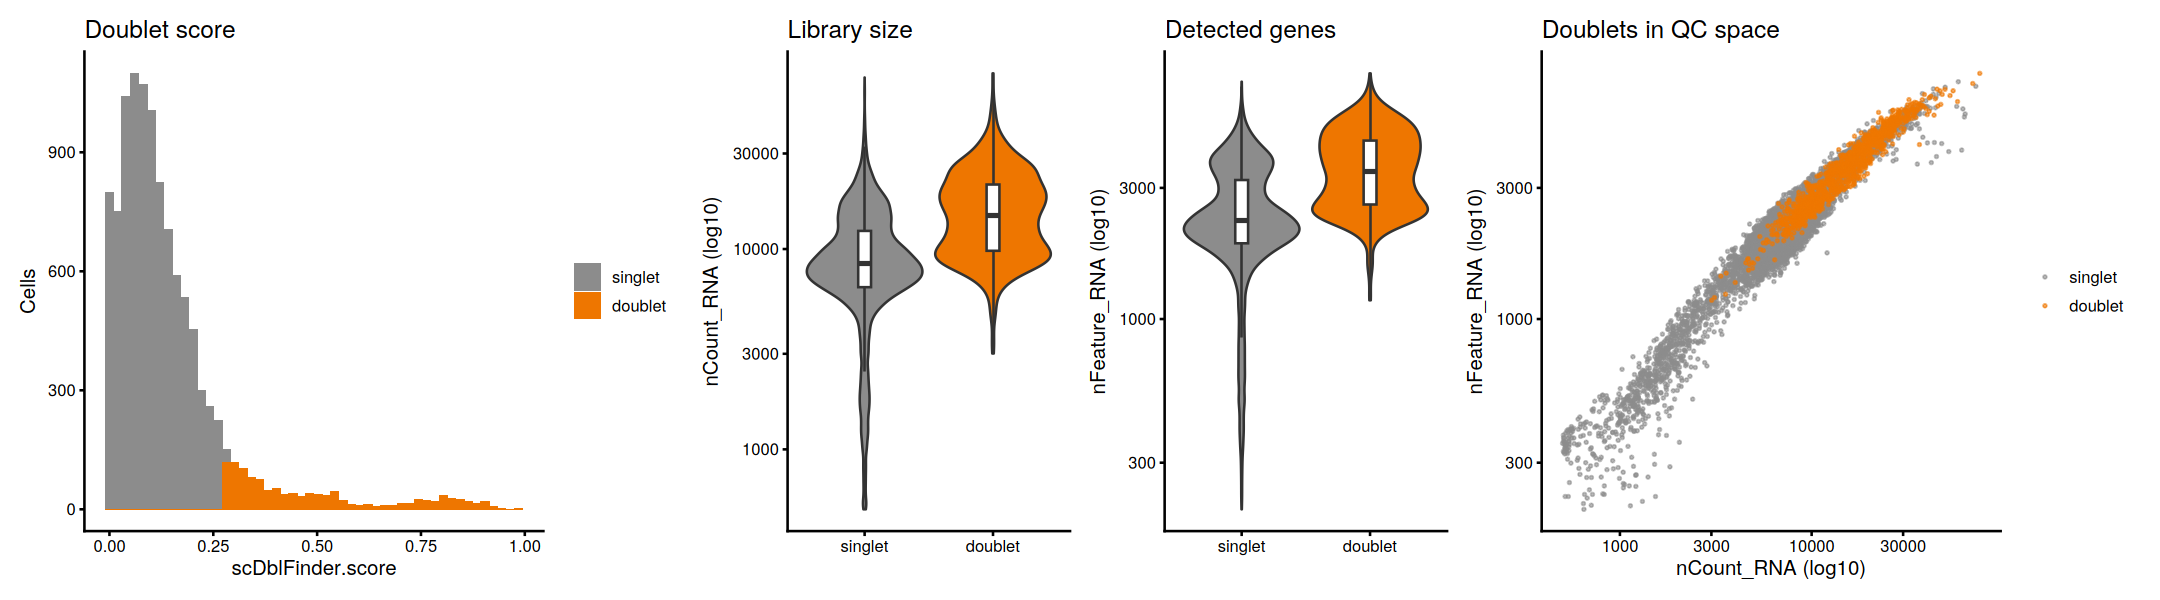

In [16]:
dbl_meta <- pbmc@meta.data[!is.na(pbmc$scDblFinder.class), ]
dbl_colours <- c(singlet = "grey55", doublet = "darkorange2")

p1 <- ggplot(dbl_meta, aes(x = scDblFinder.score, fill = scDblFinder.class)) +
  geom_histogram(bins = 50) + scale_fill_manual(values = dbl_colours) +
  labs(title = "Doublet score", x = "scDblFinder.score", y = "Cells", fill = NULL)

p2 <- ggplot(dbl_meta, aes(x = scDblFinder.class, y = nCount_RNA, fill = scDblFinder.class)) +
  geom_violin(scale = "width") + geom_boxplot(width = 0.1, outlier.shape = NA, fill = "white") +
  scale_y_log10() + scale_fill_manual(values = dbl_colours) +
  labs(title = "Library size", x = NULL, y = "nCount_RNA (log10)") + theme(legend.position = "none")

p3 <- ggplot(dbl_meta, aes(x = scDblFinder.class, y = nFeature_RNA, fill = scDblFinder.class)) +
  geom_violin(scale = "width") + geom_boxplot(width = 0.1, outlier.shape = NA, fill = "white") +
  scale_y_log10() + scale_fill_manual(values = dbl_colours) +
  labs(title = "Detected genes", x = NULL, y = "nFeature_RNA (log10)") + theme(legend.position = "none")

p4 <- ggplot(dbl_meta[order(dbl_meta$scDblFinder.class), ],
             aes(x = nCount_RNA, y = nFeature_RNA, colour = scDblFinder.class)) +
  geom_point(size = 0.4, alpha = 0.6) + scale_x_log10() + scale_y_log10() +
  scale_colour_manual(values = dbl_colours) +
  labs(title = "Doublets in QC space", x = "nCount_RNA (log10)", y = "nFeature_RNA (log10)", colour = NULL)

options(repr.plot.width = 18, repr.plot.height = 5)
p <- (p1 | p2 | p3 | p4) + plot_layout(widths = c(1.3, 0.8, 0.8, 1.3))
save_plot(p, "08_doublet_diagnostics.png", width = 18, height = 5)

pair,class,percent_coexpressing,cells
<chr>,<fct>,<dbl>,<int>
B + monocyte (MS4A1 & CD14),singlet,1.393189,9690
B + monocyte (MS4A1 & CD14),doublet,6.281407,1194
T + B (CD3E & MS4A1),singlet,1.486068,9690
T + B (CD3E & MS4A1),doublet,9.212730,1194
T + monocyte (CD3E & CD14),singlet,3.890609,9690
T + monocyte (CD3E & CD14),doublet,27.051926,1194


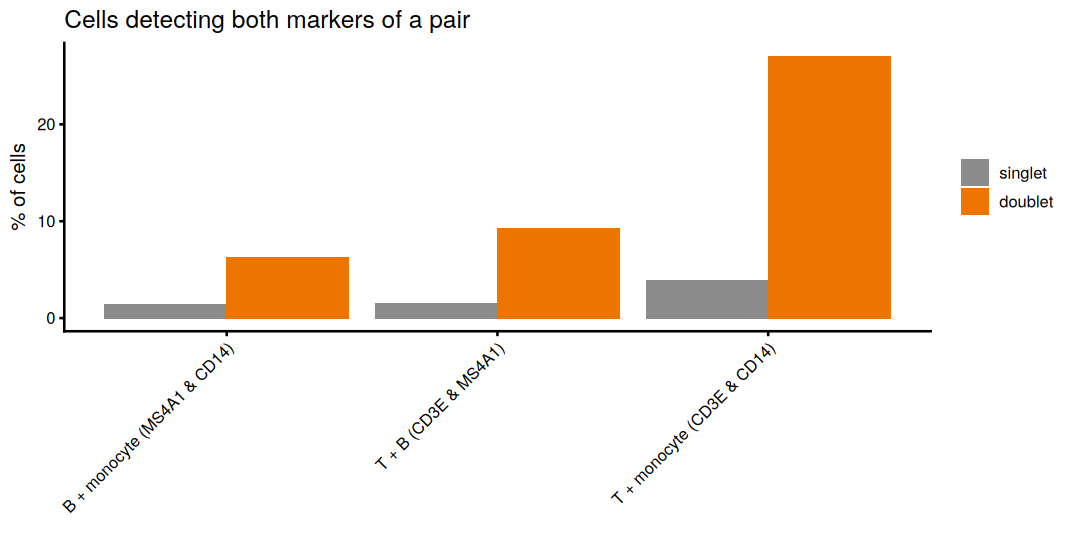

In [17]:
# Co-expression of lineage markers that should be mutually exclusive in a single cell
marker_pairs <- list(
  "T + monocyte (CD3E & CD14)"  = c("CD3E", "CD14"),
  "T + B (CD3E & MS4A1)"        = c("CD3E", "MS4A1"),
  "B + monocyte (MS4A1 & CD14)" = c("MS4A1", "CD14")
)
marker_pairs <- Filter(function(g) all(g %in% rownames(pbmc)), marker_pairs)
if (length(marker_pairs) == 0) stop("None of the marker pairs is in the data")

pair_counts <- LayerData(pbmc, assay = "RNA", layer = "counts")
coexpression <- do.call(rbind, lapply(names(marker_pairs), function(pair) {
  both <- Matrix::colSums(pair_counts[marker_pairs[[pair]], , drop = FALSE] > 0) == 2
  data.frame(pair = pair, class = pbmc$scDblFinder.class, both = both)
})) |>
  dplyr::filter(!is.na(class)) |>
  dplyr::group_by(pair, class) |>
  dplyr::summarise(percent_coexpressing = 100 * mean(both), cells = dplyr::n(), .groups = "drop")
rm(pair_counts)
coexpression

options(repr.plot.width = 9, repr.plot.height = 4.5)
p <- ggplot(coexpression, aes(x = pair, y = percent_coexpressing, fill = class)) +
  geom_col(position = "dodge") + scale_fill_manual(values = dbl_colours) +
  labs(title = "Cells detecting both markers of a pair", x = NULL, y = "% of cells", fill = NULL) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))
save_plot(p, "09_doublet_marker_coexpression.png", width = 9, height = 4.5)

> **Discussion**
> 1. Why can a simulation-based method not detect homotypic doublets?
> 2. Some singlets also co-detect *CD3E* and *CD14*. Give two explanations (hint: ambient RNA, Section 2; rare cell types). How would SoupX correction change this plot?
> 3. A cluster consists almost entirely of high-scoring cells and expresses markers of two lineages. Would you call it a new cell type?

## 4. Quality-control metrics

The metrics are computed on the **uncorrected** Cell Ranger counts (in a full analysis, on the SoupX-corrected counts; Section 2). The doublet calls from Section 3 are already in the metadata, but nothing has been removed yet.

Not every barcode in the filtered matrix is a healthy, intact single cell. The common failure modes leave characteristic signatures:

| Failure mode | Signature | Why |
|---|---|---|
| **Empty droplet / debris** (ambient RNA only) | very low `nCount_RNA` and `nFeature_RNA` | The droplet captured only free-floating RNA from lysed cells. |
| **Damaged / dying cell** | high **mitochondrial fraction**, often low counts | When the plasma membrane breaks, cytoplasmic mRNA leaks out, but transcripts inside the intact mitochondria are retained. The surviving RNA is therefore enriched for mitochondrial transcripts (Ilicic *et al.*, 2016). |
| **Doublet** | unusually high `nCount_RNA` and `nFeature_RNA`, mixed lineage markers | Two cells share one barcode (Section 3). |
| **Red-blood-cell contamination** | high **haemoglobin** fraction | Erythrocytes and their ambient RNA are almost pure haemoglobin mRNA. Not expected in a clean PBMC prep. |

Additional metrics we compute:

* **Ribosomal-protein fraction** (`RPS*` / `RPL*`): mostly biological. It is high in resting lymphocytes, which have little cytoplasm and are poised to translate. It is usually *not* used for filtering, but it explains part of the technical-looking variation.
* **Library complexity**: `log10(genes) / log10(UMIs)`. Low values mean a few genes dominate the library, for example in red blood cells (haemoglobin) or in damaged cells.

Gene sets are selected by symbol pattern. This only works because human mitochondrial genes are named `MT-*`; in mouse they are `mt-*`.

In [18]:
mark_stage("4. QC metrics")

# Scanpy: sc.pp.calculate_qc_metrics(adata, qc_vars=['mt', 'ribo', 'hb'])
pbmc[["percent.mt"]]   <- PercentageFeatureSet(pbmc, pattern = "^MT-")                  # 13 mitochondrially encoded genes
pbmc[["percent.ribo"]] <- PercentageFeatureSet(pbmc, pattern = "^RP[SL]")                # ribosomal proteins
pbmc[["percent.hb"]]   <- PercentageFeatureSet(pbmc, pattern = "^HB[ABDEGMQZ][0-9]?$")   # haemoglobins (not HBEGF, HBP1)
pbmc$log10GenesPerUMI  <- log10(pbmc$nFeature_RNA) / log10(pbmc$nCount_RNA)            # library complexity

# Always check which genes a pattern actually matched
list(mitochondrial = grep("^MT-", rownames(pbmc), value = TRUE),
     haemoglobin   = grep("^HB[ABDEGMQZ][0-9]?$", rownames(pbmc), value = TRUE),
     n_ribosomal   = length(grep("^RP[SL]", rownames(pbmc))))

$mitochondrial
 [1] "MT-ND1"  "MT-ND2"  "MT-CO1"  "MT-CO2"  "MT-ATP8" "MT-ATP6" "MT-CO3" 
 [8] "MT-ND3"  "MT-ND4L" "MT-ND4"  "MT-ND5"  "MT-ND6"  "MT-CYB" 

$haemoglobin
 [1] "HBB"  "HBD"  "HBG1" "HBG2" "HBE1" "HBZ"  "HBM"  "HBA2" "HBA1" "HBQ1"

$n_ribosomal
[1] 103

In [19]:
qc_cols <- c("nCount_RNA", "nFeature_RNA", "percent.mt", "percent.ribo", "percent.hb", "log10GenesPerUMI")
qc_summary <- t(sapply(pbmc@meta.data[, qc_cols], quantile, probs = c(0, 0.01, 0.25, 0.5, 0.75, 0.99, 1)))
round(qc_summary, 3)

,0%,1%,25%,50%,75%,99%,100%
nCount_RNA,502.000,660.680,6620.000,8773.000,13359.000,32095.320,75352.000
nFeature_RNA,58.000,229.360,1919.000,2358.000,3371.000,5549.320,7833.000
percent.mt,0.000,2.802,5.370,6.632,8.369,69.718,95.639
percent.ribo,0.964,2.265,15.888,24.364,39.152,48.993,55.755
percent.hb,0.000,0.000,0.000,0.000,0.000,0.006,1.260
log10GenesPerUMI,0.565,0.790,0.845,0.854,0.866,0.909,0.953


### Distributions of the QC metrics

Look for **shape**, not just range. Long tails and secondary modes are the populations we may want to remove. Bimodality can also be biology, though: different cell types differ in size and RNA content.

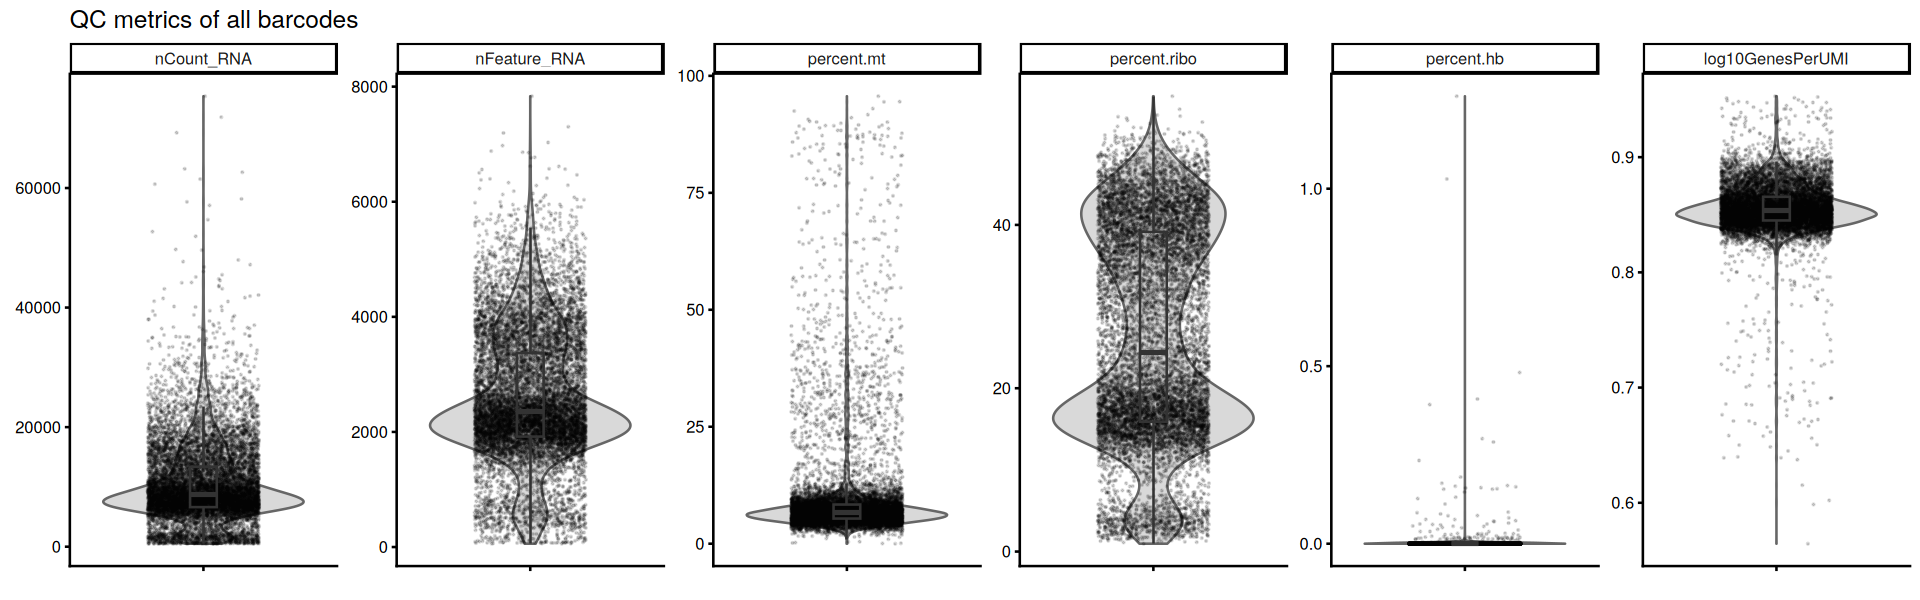

In [20]:
qc_long <- pbmc@meta.data |>
  dplyr::select(all_of(qc_cols)) |>
  tidyr::pivot_longer(everything(), names_to = "metric", values_to = "value") |>
  mutate(metric = factor(metric, levels = qc_cols))

options(repr.plot.width = 16, repr.plot.height = 5)
p <- ggplot(qc_long, aes(x = "", y = value)) +
  geom_violin(fill = "grey85", colour = "grey40", scale = "width") +
  geom_jitter(width = 0.25, size = 0.05, alpha = 0.15) +
  geom_boxplot(width = 0.12, outlier.shape = NA, fill = NA) +
  facet_wrap(~ metric, scales = "free_y", nrow = 1) +
  labs(x = NULL, y = NULL, title = "QC metrics of all barcodes")
save_plot(p, "04_qc_violins_raw.png", width = 16, height = 5)

### The most informative QC plot: UMIs vs genes, coloured by mitochondrial fraction

Healthy cells lie on a tight, roughly linear band on log–log axes: more molecules captured means more genes detected. On this plot:

* **Bottom-left**: barcodes with little RNA, i.e. empty droplets or debris.
* **High mitochondrial fraction at low depth**: damaged cells.
* **Top-right extreme**: candidate doublets.
* **Below the band** (many UMIs but few genes): low complexity, e.g. haemoglobin-dominated barcodes.

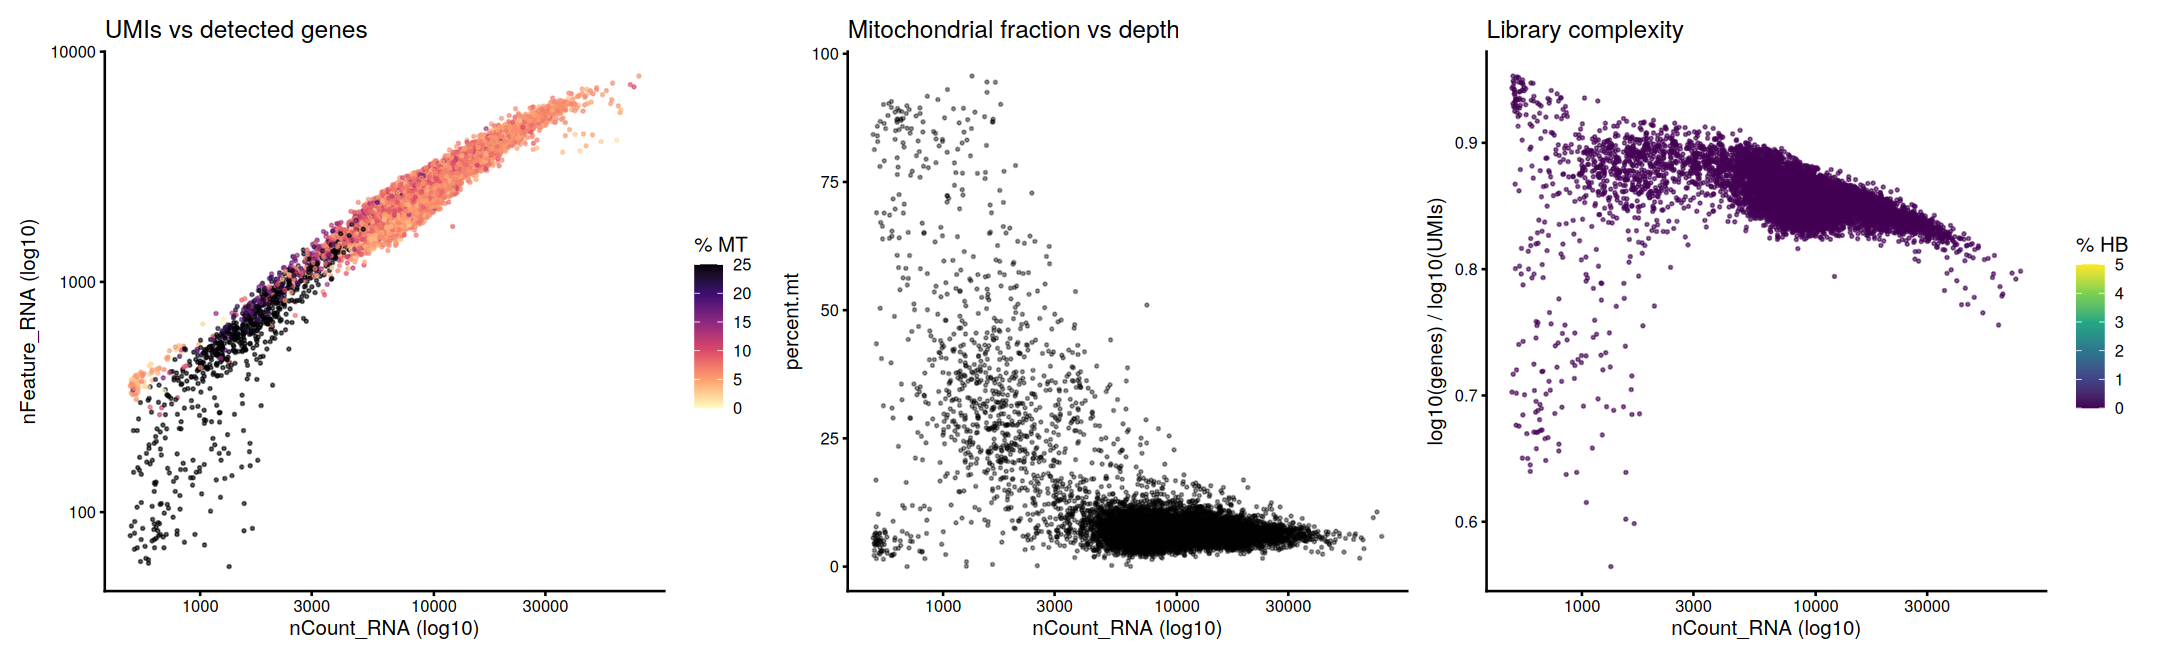

In [21]:
meta <- pbmc@meta.data

p1 <- ggplot(meta, aes(x = nCount_RNA, y = nFeature_RNA, colour = percent.mt)) +
  geom_point(size = 0.4, alpha = 0.6) +
  scale_x_log10() + scale_y_log10() +
  scale_colour_viridis_c(option = "magma", direction = -1, limits = c(0, 25), oob = scales::squish) +
  labs(title = "UMIs vs detected genes", x = "nCount_RNA (log10)", y = "nFeature_RNA (log10)", colour = "% MT")

p2 <- ggplot(meta, aes(x = nCount_RNA, y = percent.mt)) +
  geom_point(size = 0.4, alpha = 0.4) +
  scale_x_log10() +
  labs(title = "Mitochondrial fraction vs depth", x = "nCount_RNA (log10)", y = "percent.mt")

p3 <- ggplot(meta, aes(x = nCount_RNA, y = log10GenesPerUMI, colour = percent.hb)) +
  geom_point(size = 0.4, alpha = 0.6) +
  scale_x_log10() +
  scale_colour_viridis_c(limits = c(0, 5), oob = scales::squish) +
  labs(title = "Library complexity", x = "nCount_RNA (log10)", y = "log10(genes) / log10(UMIs)", colour = "% HB")

options(repr.plot.width = 18, repr.plot.height = 5.5)
p <- p1 | p2 | p3
save_plot(p, "05_qc_scatter_raw.png", width = 18, height = 5.5)

### Which genes dominate the libraries?

A handful of genes take up a large share of every library. In PBMCs these are typically the long non-coding RNA *MALAT1* (nuclear, abundant in every cell), mitochondrial transcripts, ribosomal proteins, and lineage-specific highly expressed genes such as *LYZ* or *S100A8/9* in monocytes. If one gene dominated *some* cells unusually strongly, that would point to contamination or a technical artefact.

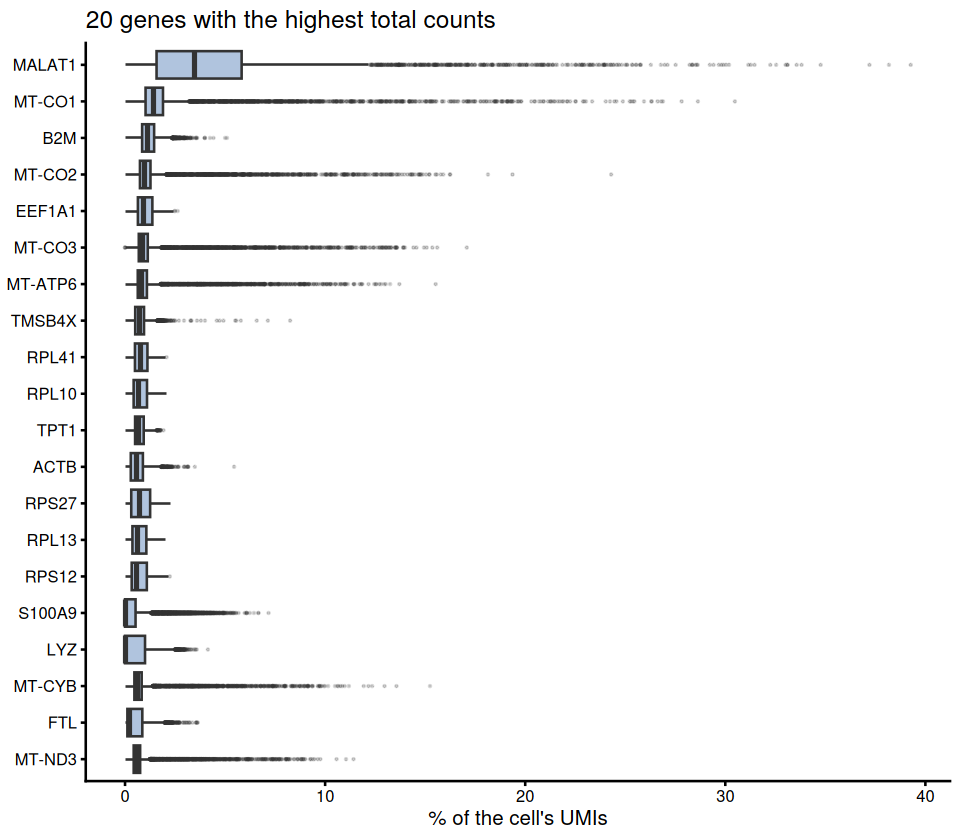

In [22]:
raw <- LayerData(pbmc, assay = "RNA", layer = "counts")
lib_size <- Matrix::colSums(raw)
top20 <- names(sort(Matrix::rowSums(raw), decreasing = TRUE))[1:20]

top_frac <- t(t(as.matrix(raw[top20, ])) / lib_size) * 100        # % of each cell's UMIs taken by each gene
top_long <- data.frame(gene = rep(top20, times = ncol(top_frac)), percent = as.vector(top_frac))
top_long$gene <- factor(top_long$gene, levels = rev(top20))
rm(top_frac)

options(repr.plot.width = 8, repr.plot.height = 7)
p <- ggplot(top_long, aes(x = percent, y = gene)) +
  geom_boxplot(outlier.size = 0.2, outlier.alpha = 0.2, fill = "lightsteelblue") +
  labs(title = "20 genes with the highest total counts", x = "% of the cell's UMIs", y = NULL)
save_plot(p, "06_highest_expressed_genes.png", width = 8, height = 7)

> **Discussion**
> 1. Neutrophils and platelets contain little RNA. In a whole-blood sample, what would a strict lower `nFeature_RNA` threshold do to them?
> 2. Cardiomyocytes and hepatocytes are packed with mitochondria. Would a 10% mitochondrial cut-off be sensible for heart or liver tissue?
> 3. Why are mitochondrial transcripts retained when the cell membrane breaks?

## 5. Choosing filtering thresholds

There are two families of approaches:

**Fixed thresholds** (e.g. `nFeature_RNA` 200–4000, `percent.mt < 10`) are simple and common in tutorials, but they encode assumptions about chemistry, sequencing depth and tissue. The same numbers can be far too strict for one dataset and too lenient for another. Osorio & Cai (2021) proposed 10% mitochondrial reads for human tissues as a general guide, but noted the strong tissue dependence.

**Data-driven thresholds** treat low-quality cells as **outliers** relative to the bulk of the data. For each metric we compute the median and the **median absolute deviation** (MAD):

$$\text{MAD} = 1.4826 \times \operatorname{median}\big(|x_i - \operatorname{median}(x)|\big)$$

The factor 1.4826 makes the MAD equal to the standard deviation for normally distributed data. Unlike the SD, the MAD is barely affected by the outliers we are trying to find. A cell is flagged if it lies more than *k* MADs from the median (McCarthy *et al.*, 2017; Lun *et al.*, 2016). Common choices:

| Metric | Scale | Direction | *k* |
|---|---|---|---|
| `nCount_RNA` | log10 (counts are right-skewed) | both tails | 5 |
| `nFeature_RNA` | log10 | both tails | 5 |
| `percent.mt` | linear | upper tail only | 3 |

A large *k* (5) is deliberately **permissive**. Current best practice (Luecken & Theis, 2019; Heumos *et al.*, 2023) is to filter gently at first and revisit suspicious populations after clustering. Removing real cell types is much harder to notice than keeping a few poor cells.

In [23]:
mark_stage("5. Filtering thresholds")

# Bounds at k MADs around the median
mad_bounds <- function(x, nmads) {
  med <- median(x)
  dev <- mad(x)                   # stats::mad() already includes the 1.4826 constant
  c(lower = med - nmads * dev, upper = med + nmads * dev)
}

bounds_counts <- 10^mad_bounds(log10(pbmc$nCount_RNA),   nmads = 5)   # back-transform to counts
bounds_genes  <- 10^mad_bounds(log10(pbmc$nFeature_RNA), nmads = 5)
bounds_mt     <-    mad_bounds(pbmc$percent.mt,          nmads = 3)

thresholds <- rbind(nCount_RNA = bounds_counts, nFeature_RNA = bounds_genes, percent.mt = bounds_mt)
write.csv(round(thresholds, 3), file.path(table_dir, "qc_mad_thresholds.csv"))
round(thresholds, 2)

,lower,upper
nCount_RNA,715.67,107542.74
nFeature_RNA,330.57,16819.73
percent.mt,0.23,13.04


In [24]:
min_genes <- 200    # absolute floor: below this a barcode carries too little information to be classified

pbmc$outlier_counts <- pbmc$nCount_RNA   < bounds_counts["lower"] | pbmc$nCount_RNA   > bounds_counts["upper"]
pbmc$outlier_genes  <- pbmc$nFeature_RNA < bounds_genes["lower"]  | pbmc$nFeature_RNA > bounds_genes["upper"]
pbmc$outlier_mt     <- pbmc$percent.mt   > bounds_mt["upper"]
pbmc$qc_pass        <- !(pbmc$outlier_counts | pbmc$outlier_genes | pbmc$outlier_mt) & pbmc$nFeature_RNA >= min_genes

# For comparison: a typical fixed-threshold rule
pbmc$qc_fixed <- pbmc$nFeature_RNA >= 200 & pbmc$nFeature_RNA <= 4000 & pbmc$percent.mt < 10

# How many barcodes fail each criterion? (a barcode can fail several)
colSums(pbmc@meta.data[, c("outlier_counts", "outlier_genes", "outlier_mt")])
table(MAD_based = pbmc$qc_pass, fixed_thresholds = pbmc$qc_fixed)

outlier_counts  outlier_genes     outlier_mt 
           136            161           1037

         fixed_thresholds
MAD_based FALSE TRUE
    FALSE  1041   59
    TRUE   1874 8011

### Visualising the thresholds

Dashed lines mark the MAD-based bounds and dotted lines the fixed thresholds. Red points would be removed by the MAD rule. Check that the removed cells really sit in the tails, and not in a distinct but healthy-looking population.

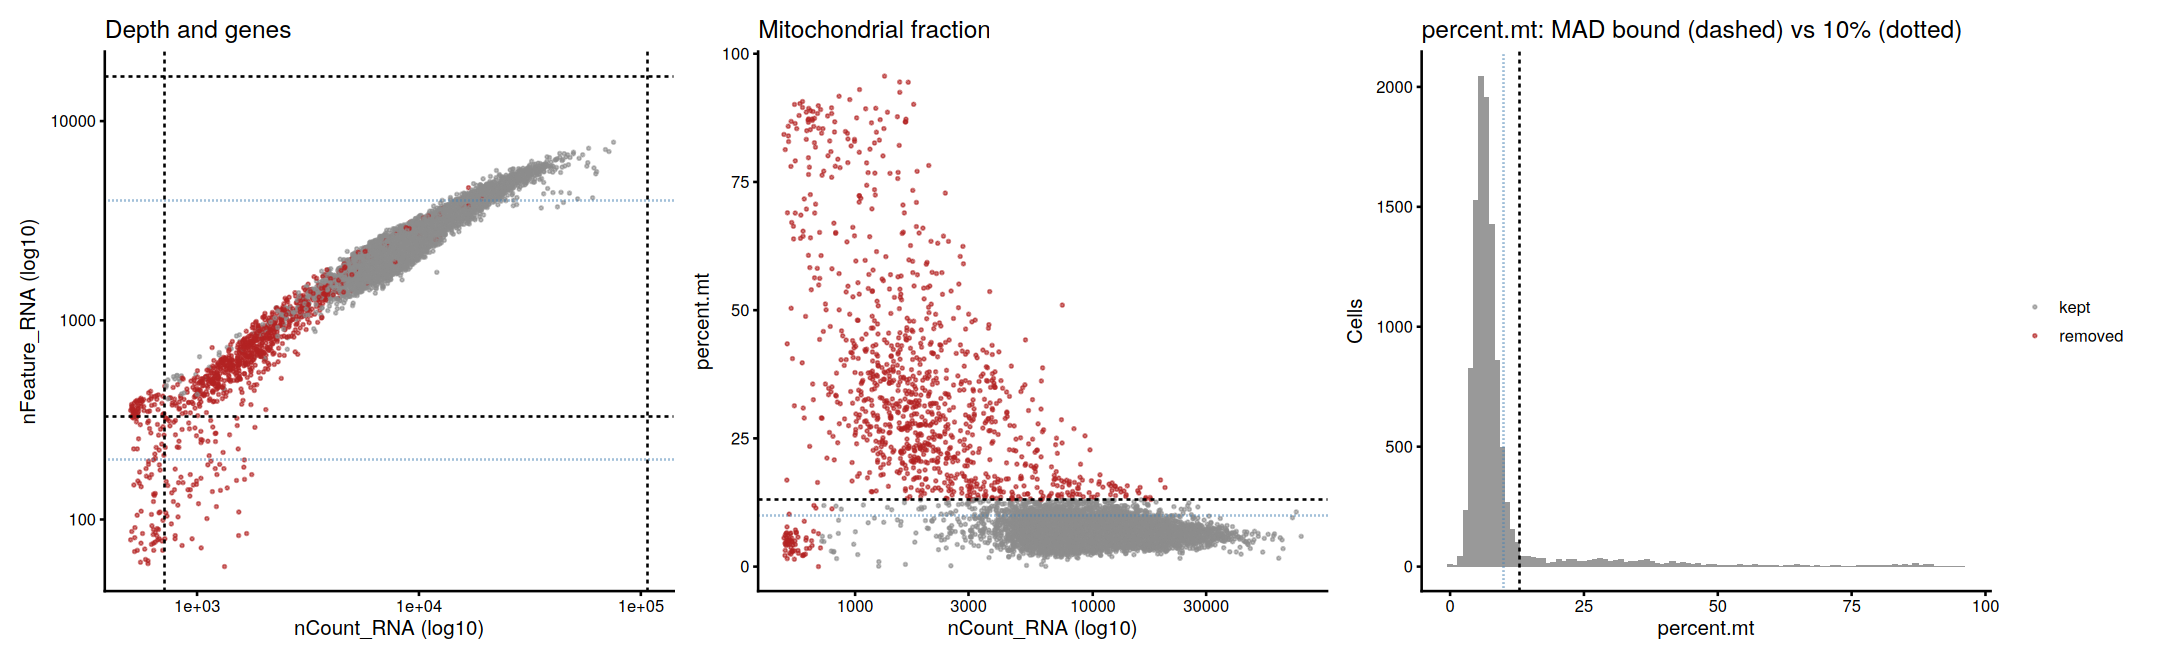

In [25]:
meta <- pbmc@meta.data
meta$qc_label <- factor(ifelse(meta$qc_pass, "kept", "removed"), levels = c("kept", "removed"))
qc_colours <- c(kept = "grey55", removed = "firebrick")

p1 <- ggplot(meta, aes(x = nCount_RNA, y = nFeature_RNA, colour = qc_label)) +
  geom_point(size = 0.4, alpha = 0.6) +
  geom_vline(xintercept = bounds_counts, linetype = "dashed") +
  geom_hline(yintercept = bounds_genes,  linetype = "dashed") +
  geom_hline(yintercept = c(200, 4000),  linetype = "dotted", colour = "steelblue") +
  scale_x_log10() + scale_y_log10() + scale_colour_manual(values = qc_colours) +
  labs(title = "Depth and genes", x = "nCount_RNA (log10)", y = "nFeature_RNA (log10)", colour = NULL)

p2 <- ggplot(meta, aes(x = nCount_RNA, y = percent.mt, colour = qc_label)) +
  geom_point(size = 0.4, alpha = 0.6) +
  geom_hline(yintercept = bounds_mt["upper"], linetype = "dashed") +
  geom_hline(yintercept = 10, linetype = "dotted", colour = "steelblue") +
  scale_x_log10() + scale_colour_manual(values = qc_colours) +
  labs(title = "Mitochondrial fraction", x = "nCount_RNA (log10)", y = "percent.mt", colour = NULL)

p3 <- ggplot(meta, aes(x = percent.mt)) +
  geom_histogram(bins = 100, fill = "grey60") +
  geom_vline(xintercept = bounds_mt["upper"], linetype = "dashed") +
  geom_vline(xintercept = 10, linetype = "dotted", colour = "steelblue") +
  labs(title = "percent.mt: MAD bound (dashed) vs 10% (dotted)", x = "percent.mt", y = "Cells")

options(repr.plot.width = 18, repr.plot.height = 5.5)
p <- (p1 | p2 | p3) + plot_layout(guides = "collect")
save_plot(p, "07_qc_thresholds.png", width = 18, height = 5.5)

**We do not remove anything yet.** The MAD outliers and the doublet calls from Section 3 are applied together in Section 6.

> **Discussion**
> 1. The MAD-based and fixed rules disagree on some cells (table above). Which cells are they, and which rule do you trust more for this dataset?
> 2. Why are counts log-transformed before computing MADs?
> 3. If one sample in a multi-sample study had much lower sequencing depth, should the MAD thresholds be computed per sample or on all cells together?

## 6. Applying the filters

A barcode is kept if it **passes the MAD-based QC** *and* is called a **singlet**. Next, genes are removed if they are detected in fewer than **3 cells**. Such genes cannot contribute to population structure, and removing them shrinks the matrix and speeds up every later step.

In [26]:
mark_stage("6. Apply filters")

pbmc$keep <- pbmc$qc_pass & (pbmc$scDblFinder.class %in% "singlet")    # %in% treats unscored (NA) barcodes as not kept

table(qc_pass = pbmc$qc_pass, doublet_class = pbmc$scDblFinder.class, useNA = "ifany")

log_step("2. Pass QC thresholds (MAD)", sum(pbmc$qc_pass), nrow(pbmc))
log_step("3. ... and called singlet", sum(pbmc$keep), nrow(pbmc))

       doublet_class
qc_pass singlet doublet <NA>
  FALSE     977      22  101
  TRUE     8713    1172    0

step,cells,genes
<chr>,<dbl>,<dbl>
1. Cell Ranger filtered barcodes,10985,36601
2. Pass QC thresholds (MAD),9885,36601


step,cells,genes
<chr>,<dbl>,<dbl>
1. Cell Ranger filtered barcodes,10985,36601
2. Pass QC thresholds (MAD),9885,36601
3. ... and called singlet,8713,36601


In [27]:
meta_before <- pbmc@meta.data                              # kept for before / after plots
pbmc <- subset(pbmc, cells = colnames(pbmc)[pbmc$keep])

min_cells <- 3
n_cells_per_gene <- Matrix::rowSums(LayerData(pbmc, assay = "RNA", layer = "counts") > 0)
genes_keep <- names(n_cells_per_gene)[n_cells_per_gene >= min_cells]
pbmc <- subset(pbmc, features = genes_keep)
rm(raw, n_cells_per_gene)

pbmc
log_step("4. Genes detected in >= 3 cells", ncol(pbmc), nrow(pbmc))

An object of class Seurat 
22180 features across 8713 samples within 1 assay 
Active assay: RNA (22180 features, 0 variable features)
 1 layer present: counts

step,cells,genes
<chr>,<dbl>,<dbl>
1. Cell Ranger filtered barcodes,10985,36601
2. Pass QC thresholds (MAD),9885,36601
3. ... and called singlet,8713,36601
4. Genes detected in >= 3 cells,8713,22180


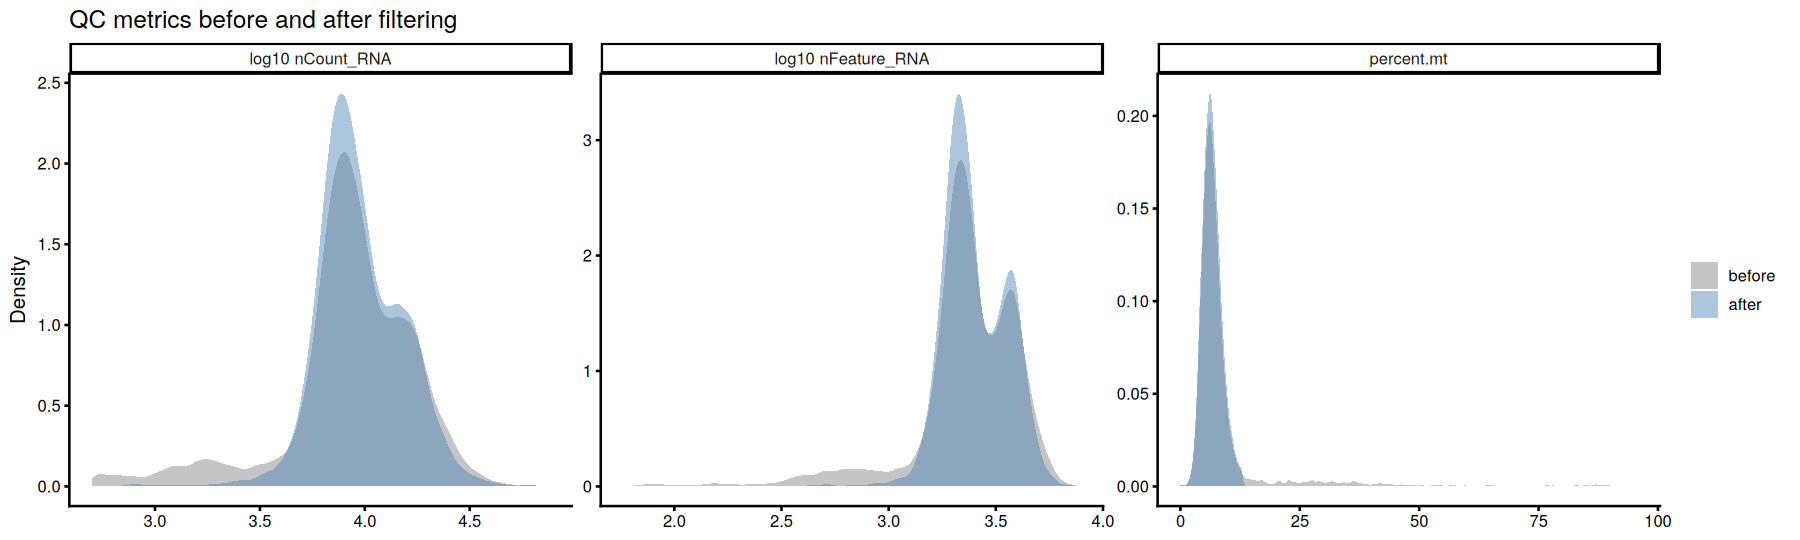

In [28]:
# Before / after: the tails we targeted should be gone, and the bulk of the distribution unchanged
cmp_cols <- c("nCount_RNA", "nFeature_RNA", "percent.mt")
before_after <- rbind(
  data.frame(stage = "before", meta_before[, cmp_cols]),
  data.frame(stage = "after",  pbmc@meta.data[, cmp_cols])
) |>
  mutate(nCount_RNA = log10(nCount_RNA), nFeature_RNA = log10(nFeature_RNA)) |>
  rename(`log10 nCount_RNA` = nCount_RNA, `log10 nFeature_RNA` = nFeature_RNA) |>
  tidyr::pivot_longer(-stage, names_to = "metric", values_to = "value") |>
  mutate(stage = factor(stage, levels = c("before", "after")))

options(repr.plot.width = 15, repr.plot.height = 4.5)
p <- ggplot(before_after, aes(x = value, fill = stage)) +
  geom_density(alpha = 0.45, colour = NA) +
  facet_wrap(~ metric, scales = "free", nrow = 1) +
  scale_fill_manual(values = c(before = "grey50", after = "steelblue")) +
  labs(title = "QC metrics before and after filtering", x = NULL, y = "Density", fill = NULL)
save_plot(p, "10_qc_before_after.png", width = 15, height = 4.5)

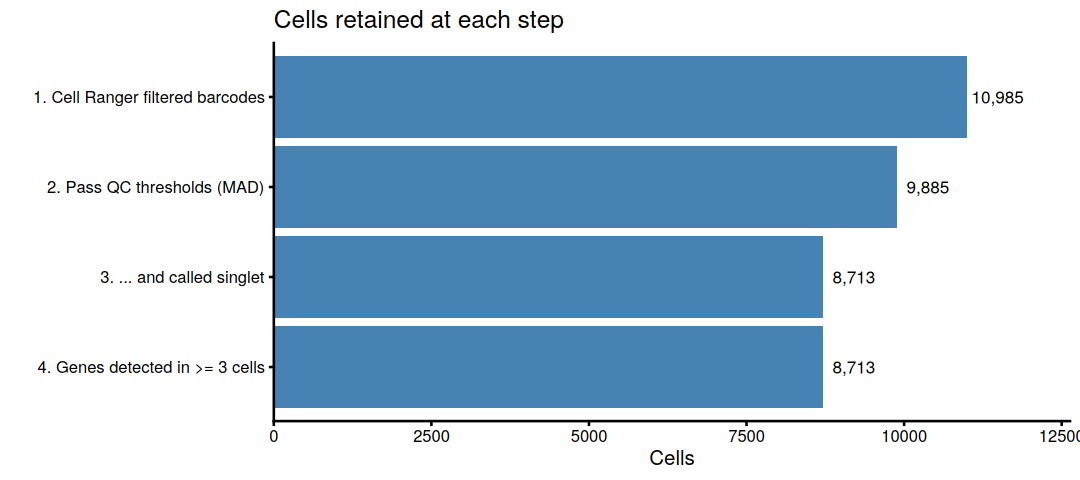

In [29]:
options(repr.plot.width = 9, repr.plot.height = 4)
p <- ggplot(qc_log, aes(x = cells, y = factor(step, levels = rev(step)))) +
  geom_col(fill = "steelblue") +
  geom_text(aes(label = format(cells, big.mark = ",")), hjust = -0.1, size = 3.5) +
  scale_x_continuous(expand = expansion(mult = c(0, 0.15))) +
  labs(title = "Cells retained at each step", x = "Cells", y = NULL)
write.csv(qc_log, file.path(table_dir, "cells_genes_per_step.csv"), row.names = FALSE)
save_plot(p, "11_cells_per_step.png", width = 9, height = 4)

## 7. Normalization

### Why normalize?

The UMI count of gene *g* in cell *i* reflects the gene's true expression **and** cell-specific technical factors: capture efficiency, reverse-transcription efficiency and sequencing depth. These factors multiply the expression of *all* genes in a cell, so a cell sequenced twice as deeply shows roughly twice the counts for every gene. Without correction, the largest source of variation between cells would be library size, not biology.

### What `LogNormalize` does

For count $x_{gi}$ of gene $g$ in cell $i$ with library size $N_i = \sum_g x_{gi}$:

$$y_{gi} = \log\left(1 + \frac{x_{gi}}{N_i} \times 10^4\right)$$

1. **Scale**: divide by the library size, so every cell has the same total (10,000 here, i.e. "counts per 10k"). This assumes that most differences in total counts are technical.
2. **Log-transform**: makes multiplicative differences (fold changes) additive, compresses the range of very highly expressed genes, and partly stabilises the variance. The **pseudocount 1** keeps zeros at zero.

### Alternatives (for awareness)

| Method | Idea | Reference |
|---|---|---|
| scran pooling | size factors estimated from pools of cells; robust to composition differences | Lun, Bach & Marioni, 2016 |
| SCTransform | regularised negative-binomial regression on library size; returns Pearson residuals | Hafemeister & Satija, 2019; Choudhary & Satija, 2022 |
| Analytic Pearson residuals | closed-form residuals of a Poisson / NB model | Lause, Berens & Kobak, 2021 |

In a systematic comparison, the simple shifted logarithm followed by PCA performed **as well as or better than** more sophisticated transformations on many benchmarks (Ahlmann-Eltze & Huber, 2023). It is a sound default. Its known weakness is that results depend somewhat on the pseudocount and scale factor (Lun, 2018).

In [30]:
mark_stage("7. Normalization")

# How different are library sizes? (a 10-fold range is common even after QC)
lib_q <- quantile(pbmc$nCount_RNA, c(0.01, 0.5, 0.99))
c(round(lib_q), fold_range_1st_to_99th_percentile = round(unname(lib_q[3] / lib_q[1]), 1))

1%                               50% 
                           3063.0                            8878.0 
                              99% fold_range_1st_to_99th_percentile 
                          29821.0                               9.7

In [31]:
# Scanpy: sc.pp.normalize_total(adata, target_sum=1e4); sc.pp.log1p(adata)
pbmc <- NormalizeData(pbmc, normalization.method = "LogNormalize", scale.factor = 1e4)
Layers(pbmc[["RNA"]])        # a "data" layer now sits next to "counts"

Normalizing layer: counts



[1] "counts" "data"

In [32]:
# Check the formula by hand for one gene in one cell
counts_mat <- LayerData(pbmc, assay = "RNA", layer = "counts")
norm_mat   <- LayerData(pbmc, assay = "RNA", layer = "data")
example_gene <- if ("ACTB" %in% rownames(pbmc)) "ACTB" else names(which.max(Matrix::rowMeans(counts_mat)))
example_cell <- colnames(pbmc)[1]

raw_value <- counts_mat[example_gene, example_cell]
library_n <- pbmc@meta.data[example_cell, "nCount_RNA"]
c(raw_count = raw_value, library_size = library_n,
  by_hand = log1p(raw_value / library_n * 1e4),
  seurat  = norm_mat[example_gene, example_cell])

raw_count library_size      by_hand       seurat 
   27.000000  1628.000000     5.117081     5.117081

### Effect 1: expression no longer tracks library size

Before normalization, almost every gene's counts rise with the cell's library size, because sampling depth affects all genes. After normalization this dependence should largely disappear. We test this with the Spearman correlation between each gene's expression and library size, for the 500 most highly expressed genes. Some correlation is expected to remain: larger cells (e.g. monocytes) genuinely contain more RNA, and the log with a pseudocount does not fully remove depth effects for lowly expressed genes.

raw counts log-normalized 
     0.5840686      0.1409499

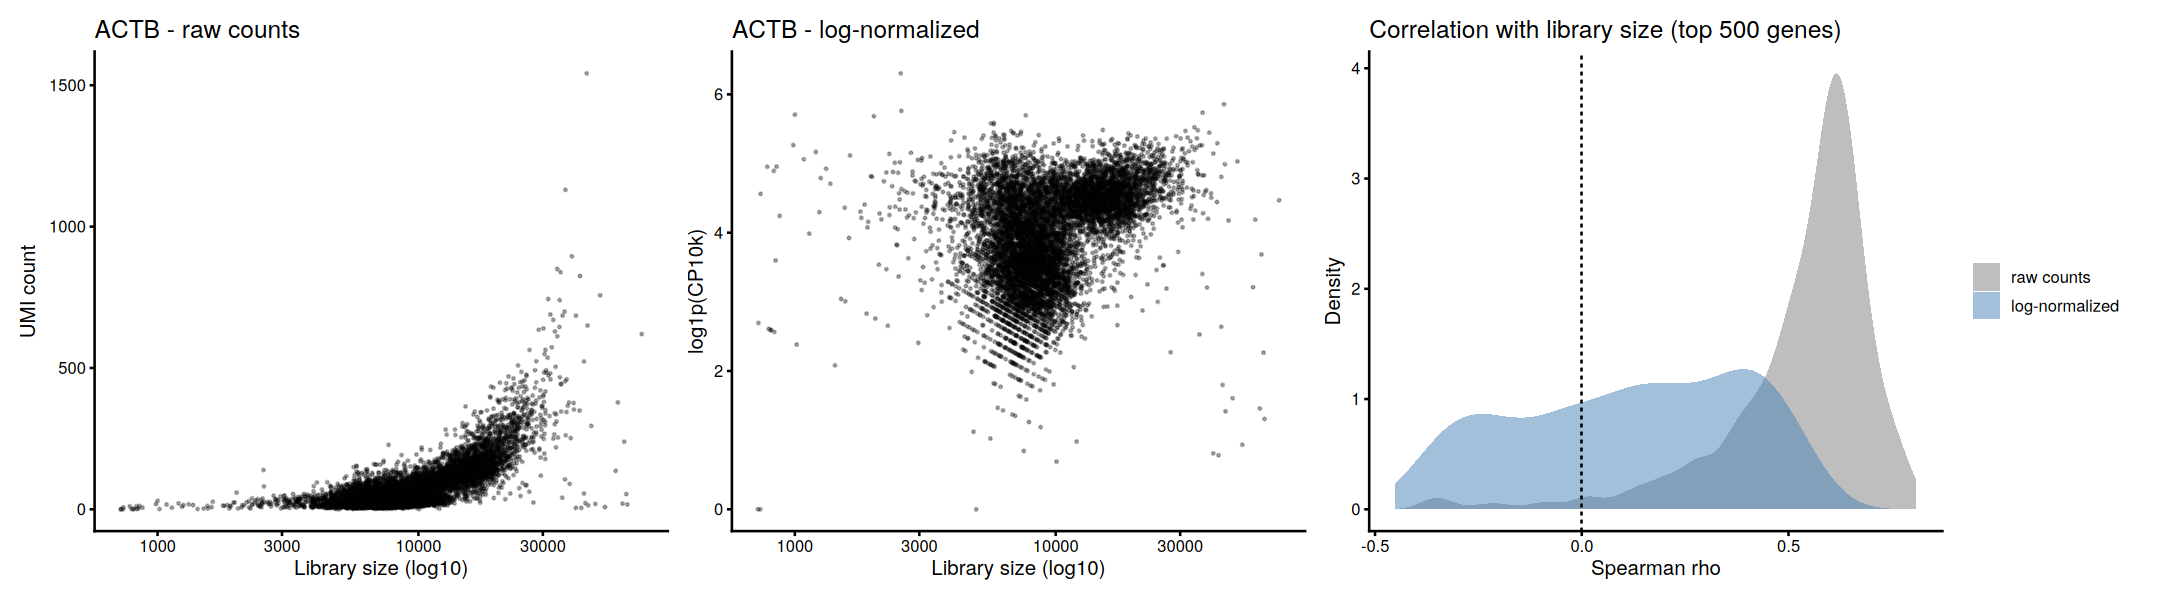

In [33]:
top500 <- names(sort(Matrix::rowMeans(counts_mat), decreasing = TRUE))[1:500]
lib    <- pbmc@meta.data$nCount_RNA

cor_with_depth <- data.frame(
  gene  = rep(top500, 2),
  stage = factor(rep(c("raw counts", "log-normalized"), each = 500), levels = c("raw counts", "log-normalized")),
  rho   = c(apply(as.matrix(counts_mat[top500, ]), 1, cor, y = lib, method = "spearman"),
            apply(as.matrix(norm_mat[top500, ]),   1, cor, y = lib, method = "spearman"))
)
tapply(cor_with_depth$rho, cor_with_depth$stage, median)

example_df <- data.frame(lib = lib, raw = counts_mat[example_gene, ], norm = norm_mat[example_gene, ])
p1 <- ggplot(example_df, aes(x = lib, y = raw)) + geom_point(size = 0.3, alpha = 0.3) + scale_x_log10() +
  labs(title = paste(example_gene, "- raw counts"), x = "Library size (log10)", y = "UMI count")
p2 <- ggplot(example_df, aes(x = lib, y = norm)) + geom_point(size = 0.3, alpha = 0.3) + scale_x_log10() +
  labs(title = paste(example_gene, "- log-normalized"), x = "Library size (log10)", y = "log1p(CP10k)")
p3 <- ggplot(cor_with_depth, aes(x = rho, fill = stage)) +
  geom_density(alpha = 0.5, colour = NA) + geom_vline(xintercept = 0, linetype = "dashed") +
  scale_fill_manual(values = c(`raw counts` = "grey50", `log-normalized` = "steelblue")) +
  labs(title = "Correlation with library size (top 500 genes)", x = "Spearman rho", y = "Density", fill = NULL)

options(repr.plot.width = 18, repr.plot.height = 5)
p <- p1 | p2 | p3
save_plot(p, "12_normalization_library_size.png", width = 18, height = 5)

### Effect 2: the mean–variance relationship

For raw UMI counts, variance grows with the mean. Pure sampling noise (Poisson) gives variance = mean, the dashed line. Real data lie **above** the line for highly expressed genes, which is **overdispersion** from biological heterogeneity and technical variation. It is the reason a negative-binomial model fits UMI data better than a Poisson one.

After log-normalization the variance no longer increases steadily with the mean. Highly expressed genes no longer dominate purely because of their magnitude. However, the relationship is not flat, and that is why the next step (HVG selection) models it explicitly.

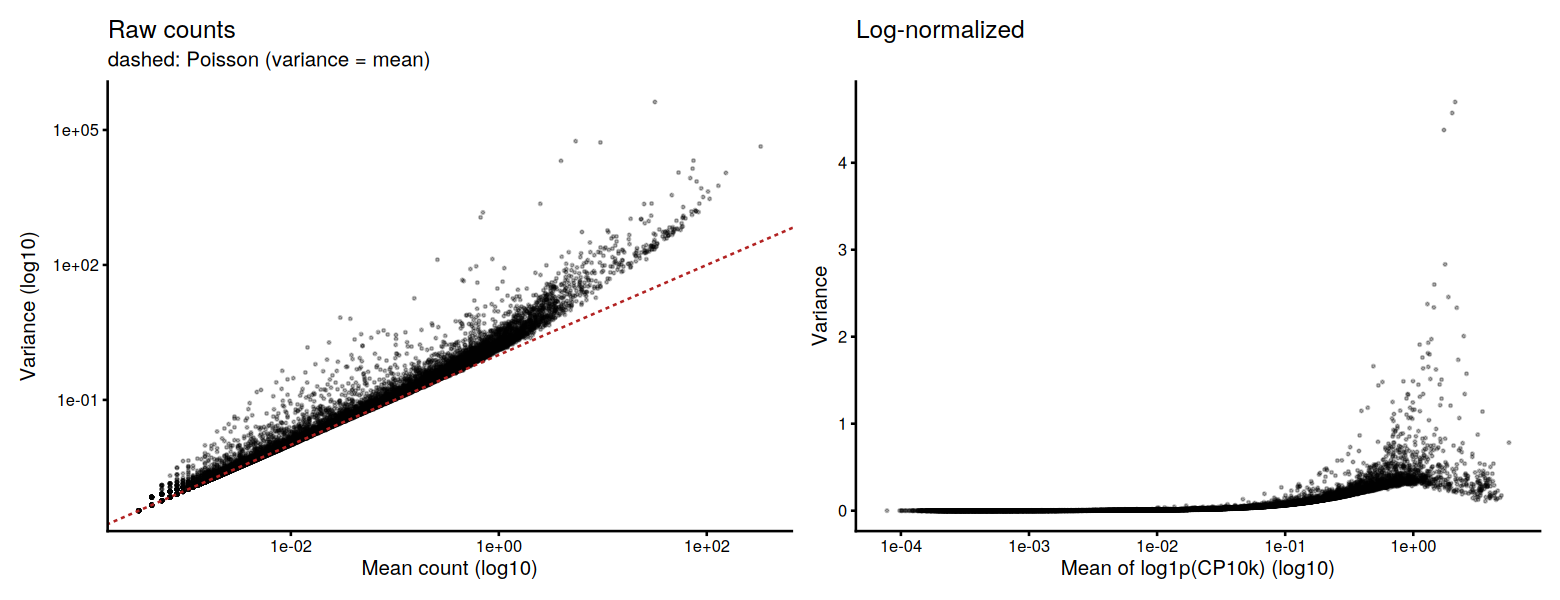

In [34]:
gene_mean_var <- function(m) {
  mu <- Matrix::rowMeans(m)
  v  <- (Matrix::rowMeans(m^2) - mu^2) * ncol(m) / (ncol(m) - 1)    # sample variance from sparse sums
  data.frame(mean = mu, variance = v)
}
mv_raw  <- gene_mean_var(counts_mat)
mv_norm <- gene_mean_var(norm_mat)

p1 <- ggplot(mv_raw[mv_raw$mean > 0, ], aes(x = mean, y = variance)) +
  geom_point(size = 0.3, alpha = 0.3) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = "firebrick") +
  scale_x_log10() + scale_y_log10() +
  labs(title = "Raw counts", subtitle = "dashed: Poisson (variance = mean)", x = "Mean count (log10)", y = "Variance (log10)")

p2 <- ggplot(mv_norm[mv_norm$mean > 0, ], aes(x = mean, y = variance)) +
  geom_point(size = 0.3, alpha = 0.3) +
  scale_x_log10() +
  labs(title = "Log-normalized", x = "Mean of log1p(CP10k) (log10)", y = "Variance")

options(repr.plot.width = 13, repr.plot.height = 5)
p <- p1 | p2
save_plot(p, "13_mean_variance.png", width = 13, height = 5)

> **Discussion**
> 1. Library-size normalization assumes that most of the difference in total counts between cells is technical. When is that assumption violated? (Think of cell types that differ greatly in size or RNA content.)
> 2. What does the pseudocount do to genes with a count of 0? Would a pseudocount of 0.1 change the result?
> 3. Why can't we simply compare raw counts between two cells?

## 8. Highly variable genes (feature selection)

### Why select genes?

Of the ~25,000 genes detected after filtering, most are either not expressed in a given cell type or vary only through sampling noise. Including them in PCA adds noise without adding information. **Feature selection** keeps the genes whose cell-to-cell variation exceeds what is expected from their mean expression. These genes typically include lineage markers and genes of active programmes.

### How the `vst` method works (Stuart *et al.*, 2019)

1. For each gene, compute mean and variance of the **raw counts**.
2. Fit a smooth curve (loess) of log(variance) against log(mean). This curve is the **expected variance** for a gene of that mean, which captures technical noise plus typical overdispersion.
3. **Standardize** each gene's counts using its observed mean and its *expected* standard deviation, clipping extreme values at √(number of cells) so single outlier cells cannot dominate.
4. The variance of these standardized values is the **standardized variance**. Genes are ranked by it and the top *n* are selected.

The **number of HVGs** (here 2,000, the Seurat default) is a tuning parameter. Results are usually robust between ~1,000 and 5,000, but rare populations defined by a few genes may need more. For several samples, select HVGs per batch and combine them, so batch-specific genes do not dominate.

In [35]:
mark_stage("8. Highly variable genes")

# Scanpy: sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=2000)  (seurat_v3 = vst, on raw counts)
n_hvg <- 2000
pbmc <- FindVariableFeatures(pbmc, selection.method = "vst", nfeatures = n_hvg)
hvg_genes <- VariableFeatures(pbmc)            # ordered: most variable first

hvf <- HVFInfo(pbmc, method = "vst")
colnames(hvf) <- sub("^vst\\.", "", colnames(hvf))      # mean, variance, variance.expected, variance.standardized
hvf$gene     <- rownames(hvf)
hvf$hvg      <- hvf$gene %in% hvg_genes
hvf$hvg_rank <- match(hvf$gene, hvg_genes)

write.csv(hvf[hvf$hvg, ][order(hvf$hvg_rank[hvf$hvg]), ], file.path(table_dir, "highly_variable_genes.csv"), row.names = FALSE)
head(hvg_genes, 30)
c(mitochondrial_HVGs = sum(grepl("^MT-", hvg_genes)), ribosomal_HVGs = sum(grepl("^RP[SL]", hvg_genes)))

Finding variable features for layer counts



[1] "IGLC1"   "IGLC3"   "CXCL10"  "PTGDS"   "JCHAIN"  "IGKC"    "GZMB"   
 [8] "MZB1"    "FCER1A"  "TXNDC5"  "CDKN1C"  "ITM2C"   "LILRA4"  "LYPD2"  
[15] "GNLY"    "C1QA"    "PPBP"    "GP1BB"   "C1QB"    "CD1C"    "SCT"    
[22] "PF4"     "DERL3"   "IGHA2"   "TYMS"    "CCL4"    "CLEC10A" "TCL1A"  
[29] "CAVIN2"  "TUBB1"

mitochondrial_HVGs     ribosomal_HVGs 
                 1                  0

**Read the top of the list.** Without any clustering, the most variable genes in PBMCs are usually recognisable markers, for example of platelets (*PPBP*, *PF4*), monocytes (*LYZ*, *S100A8/9*), B cells (immunoglobulin genes) and NK / cytotoxic cells (*GNLY*, *NKG7*). If the list were dominated by mitochondrial, ribosomal or stress genes, that would point to a technical problem.

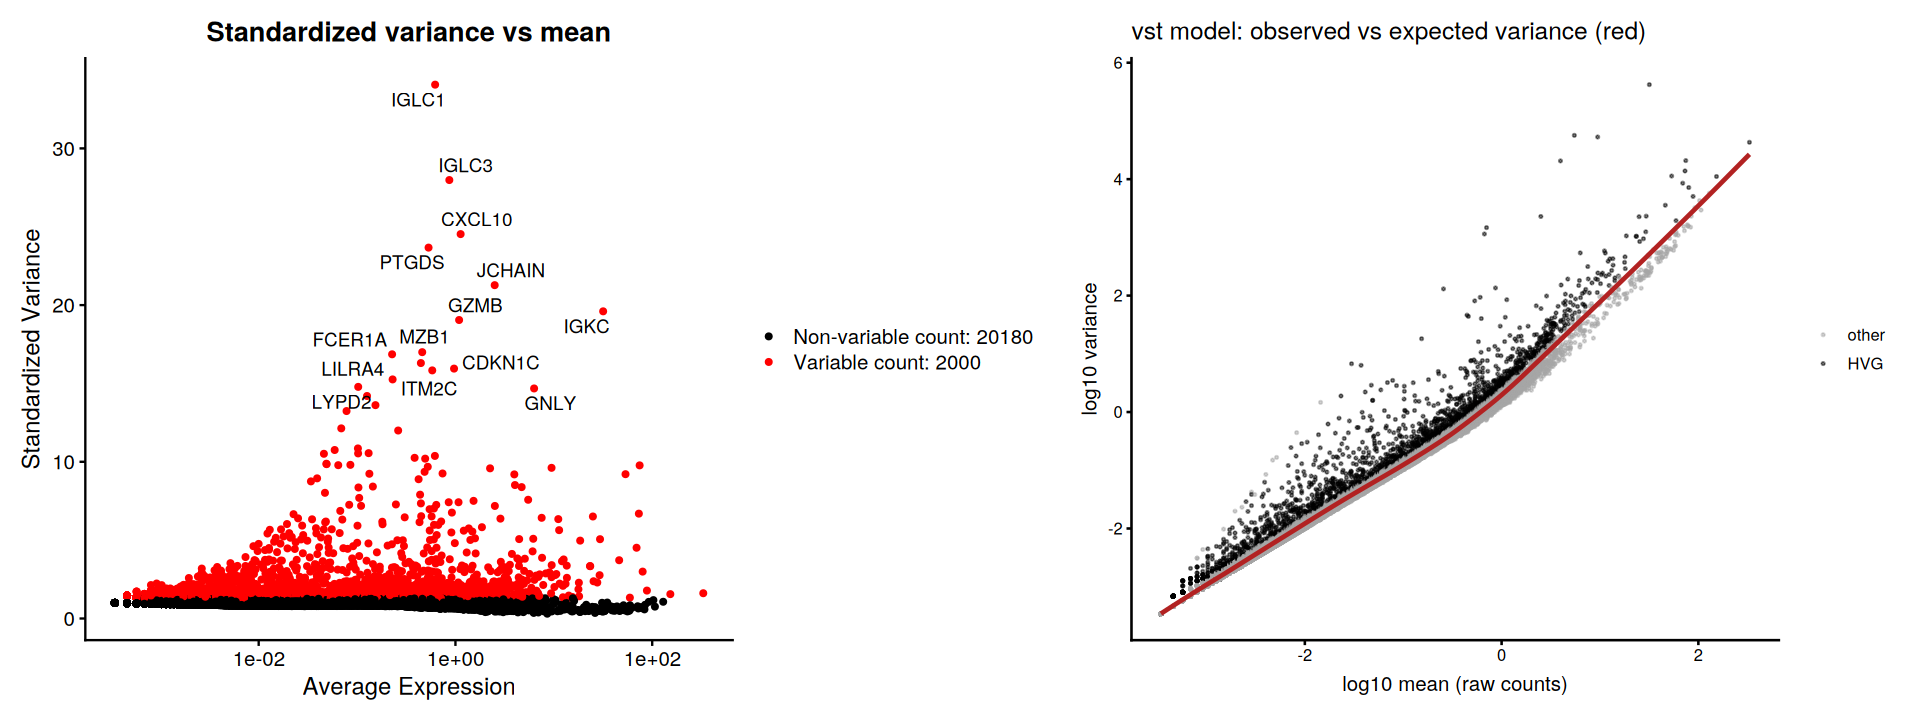

In [36]:
top15 <- head(hvg_genes, 15)

# Left: Seurat's standard plot. Right: the vst model, observed variance vs the fitted expected variance
p1 <- LabelPoints(plot = VariableFeaturePlot(pbmc), points = top15, repel = TRUE, xnudge = 0, ynudge = 0) +
  labs(title = "Standardized variance vs mean")

hvf_plot <- hvf[hvf$mean > 0, ]
hvf_plot <- hvf_plot[order(hvf_plot$mean), ]
p2 <- ggplot(hvf_plot, aes(x = log10(mean), y = log10(variance))) +
  geom_point(aes(colour = hvg), size = 0.3, alpha = 0.5) +
  geom_line(aes(y = log10(variance.expected)), colour = "firebrick", linewidth = 1) +
  scale_colour_manual(values = c(`FALSE` = "grey65", `TRUE` = "black"), labels = c("other", "HVG")) +
  labs(title = "vst model: observed vs expected variance (red)", x = "log10 mean (raw counts)", y = "log10 variance", colour = NULL)

options(repr.plot.width = 16, repr.plot.height = 6)
p <- p1 | p2
save_plot(p, "14_hvg_selection.png", width = 16, height = 6)

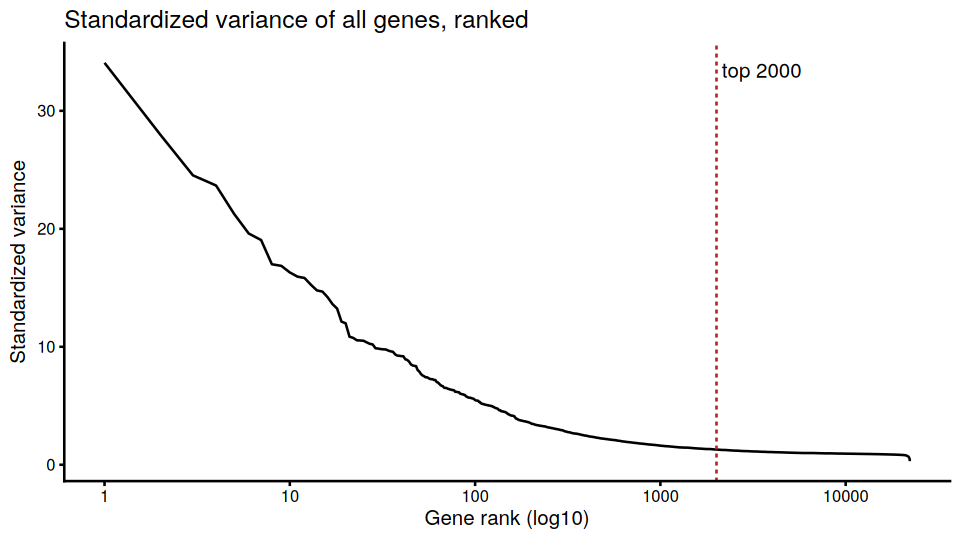

In [37]:
# Where is the cut-off? Standardized variance by rank
ranked <- hvf[order(-hvf$variance.standardized), ]
ranked$rank <- seq_len(nrow(ranked))

options(repr.plot.width = 8, repr.plot.height = 4.5)
p <- ggplot(ranked, aes(x = rank, y = variance.standardized)) +
  geom_line() +
  geom_vline(xintercept = n_hvg, linetype = "dashed", colour = "firebrick") +
  scale_x_log10() +
  annotate("text", x = n_hvg, y = max(ranked$variance.standardized), label = paste0(" top ", n_hvg), hjust = 0, vjust = 1) +
  labs(title = "Standardized variance of all genes, ranked", x = "Gene rank (log10)", y = "Standardized variance")
save_plot(p, "15_hvg_rank.png", width = 8, height = 4.5)

### HVGs vs highly expressed, non-variable genes

Variable is not the same as highly expressed. Top HVGs are typically **bimodal**: high in one cell population and near zero elsewhere. Highly expressed non-HVGs (often housekeeping genes) are expressed at a similar level in almost every cell, so they carry little information about cell identity.

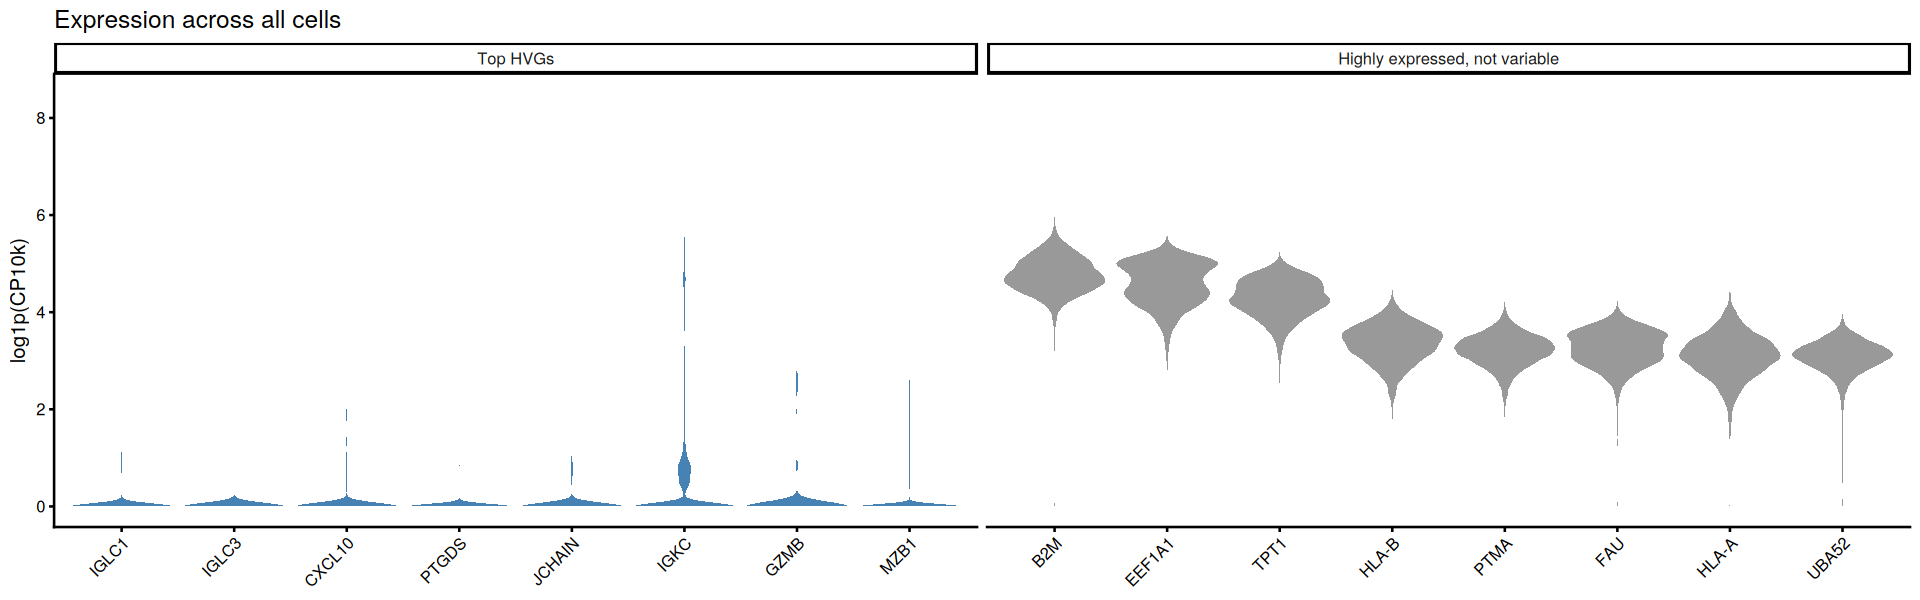

In [38]:
top_hvg      <- head(hvg_genes, 8)
candidates   <- hvf[!hvf$hvg & !grepl("^(MT-|RP[SL])", hvf$gene), ]          # non-HVGs, excluding MT / ribosomal genes
stable_genes <- head(candidates$gene[order(-candidates$mean)], 8)           # the 8 most highly expressed of them

genes_show <- c(top_hvg, stable_genes)
expr <- as.matrix(norm_mat[genes_show, ])
expr_long <- data.frame(
  gene  = factor(rep(genes_show, times = ncol(expr)), levels = genes_show),
  group = factor(rep(ifelse(genes_show %in% top_hvg, "Top HVGs", "Highly expressed, not variable"), times = ncol(expr)),
                 levels = c("Top HVGs", "Highly expressed, not variable")),
  value = as.vector(expr)
)
rm(expr)

options(repr.plot.width = 16, repr.plot.height = 5)
p <- ggplot(expr_long, aes(x = gene, y = value, fill = group)) +
  geom_violin(scale = "width", colour = NA) +
  facet_wrap(~ group, scales = "free_x") +
  scale_fill_manual(values = c("Top HVGs" = "steelblue", "Highly expressed, not variable" = "grey60")) +
  labs(x = NULL, y = "log1p(CP10k)", title = "Expression across all cells") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1), legend.position = "none")
save_plot(p, "16_hvg_vs_stable_genes.png", width = 16, height = 5)

> **Discussion**
> 1. Why not simply take the genes with the highest raw variance? (Look at the mean–variance plot in Section 7.)
> 2. A rare population (0.5% of cells) is defined by five marker genes. Would they be selected as HVGs? What could you change?
> 3. Why is `vst` computed on raw counts rather than on log-normalized data?

## 9. Scaling

### What scaling does

`ScaleData` turns each gene's log-normalized expression into a **z-score**:

$$z_{gi} = \frac{y_{gi} - \bar{y}_g}{s_g}, \qquad z_{gi} \leftarrow \min(z_{gi},\ 10)$$

* **Centering** (subtract the gene's mean) is required for PCA, which describes variation around the mean.
* **Scaling to unit variance** gives every gene equal weight. Without it, the PCs would be driven by the few genes with the largest variance on the log scale, which are mostly very highly expressed genes. With it, a moderately expressed but very informative transcription factor counts as much as *LYZ*.
* **Clipping** at 10 (`scale.max`) stops a handful of extreme cells from dominating a gene.

Only the HVGs are scaled, because only they enter the PCA. The result is stored in the `scale.data` layer, a dense matrix.

**Scanpy note.** `sc.pp.pca` centers the data but does not scale it to unit variance unless you run `sc.pp.scale` first. Both conventions exist: unit variance up-weights lowly expressed genes, including their noise.

In [39]:
mark_stage("9. Scaling")

# Before scaling: how much of the total variance do the 10 most variable HVGs carry?
var_before <- mv_norm[hvg_genes, "variance"]
names(var_before) <- hvg_genes
c(share_of_total_variance_top10_genes_percent = round(100 * sum(sort(var_before, decreasing = TRUE)[1:10]) / sum(var_before), 1),
  equal_share_if_all_genes_equal_percent = round(100 * 10 / length(hvg_genes), 1))

share_of_total_variance_top10_genes_percent 
                                        8.9 
     equal_share_if_all_genes_equal_percent 
                                        0.5

In [40]:
# Scanpy: sc.pp.scale(adata, max_value=10)
pbmc <- ScaleData(pbmc, features = hvg_genes)     # defaults: do.center = TRUE, do.scale = TRUE, scale.max = 10
scaled <- LayerData(pbmc, assay = "RNA", layer = "scale.data")

var_after <- apply(scaled, 1, var)
c(genes_scaled = nrow(scaled), cells = ncol(scaled),
  mean_of_gene_means = round(mean(rowMeans(scaled)), 4),
  median_gene_variance = round(median(var_after), 3),
  percent_values_clipped_at_10 = round(100 * mean(scaled >= 10), 3))

Centering and scaling data matrix



genes_scaled                        cells 
                   2000.0000                    8713.0000 
          mean_of_gene_means         median_gene_variance 
                     -0.0068                       0.9950 
percent_values_clipped_at_10 
                      0.0870

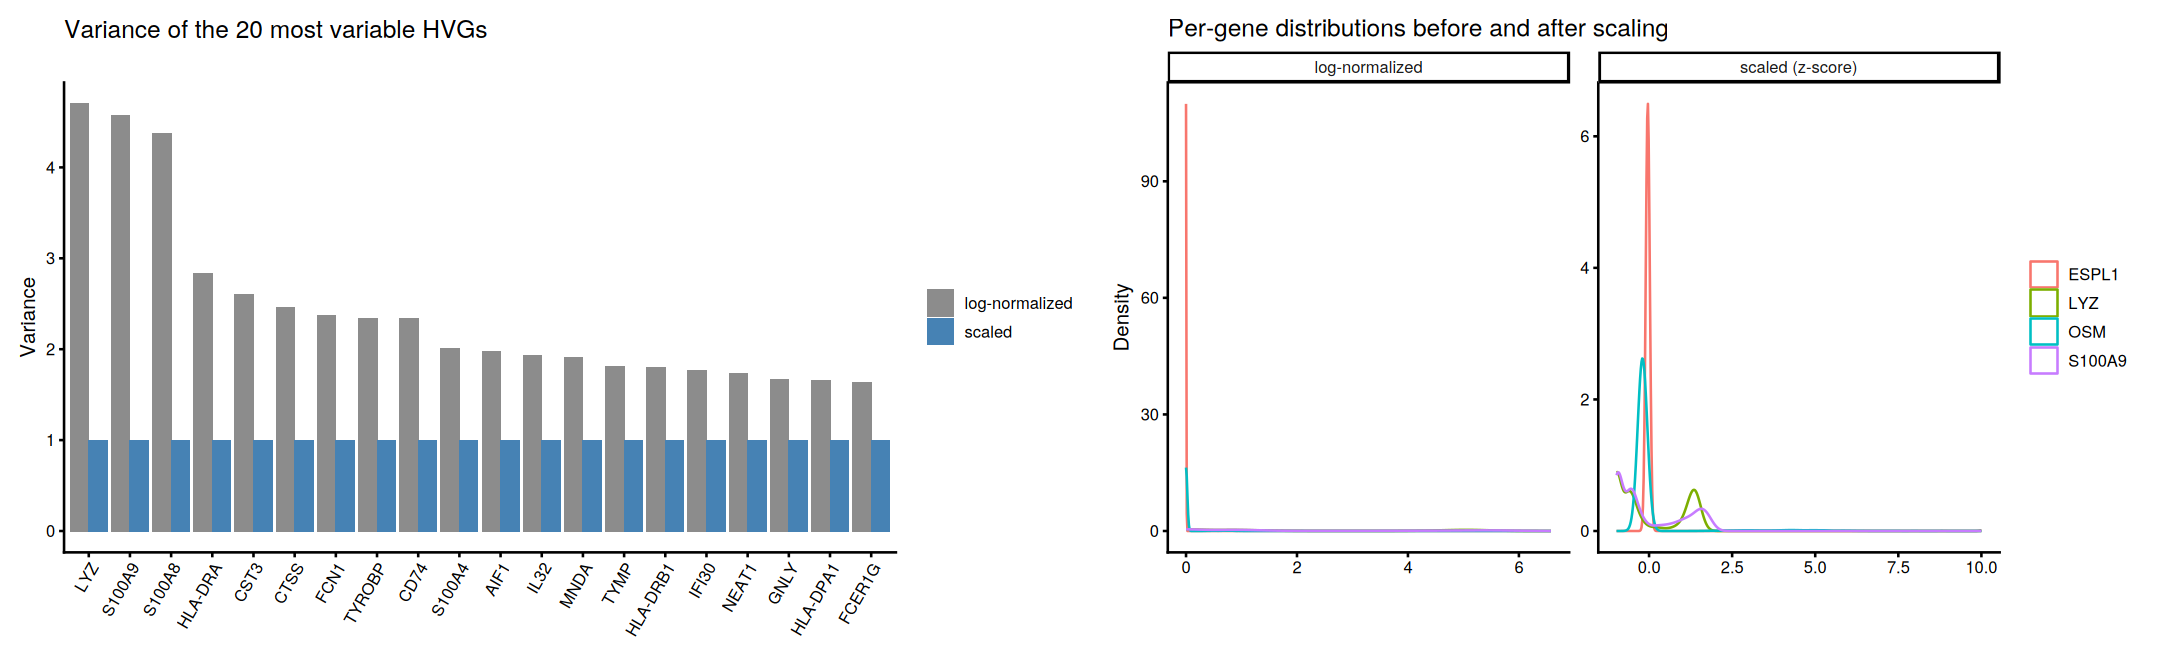

In [41]:
top20_var <- names(sort(var_before, decreasing = TRUE))[1:20]
var_df <- data.frame(
  gene  = factor(rep(top20_var, 2), levels = top20_var),
  stage = factor(rep(c("log-normalized", "scaled"), each = 20), levels = c("log-normalized", "scaled")),
  variance = c(var_before[top20_var], var_after[top20_var])
)
p1 <- ggplot(var_df, aes(x = gene, y = variance, fill = stage)) +
  geom_col(position = "dodge") +
  scale_fill_manual(values = c(`log-normalized` = "grey55", scaled = "steelblue")) +
  labs(title = "Variance of the 20 most variable HVGs", x = NULL, y = "Variance", fill = NULL) +
  theme(axis.text.x = element_text(angle = 60, hjust = 1))

example_genes <- c(top20_var[1:2], tail(hvg_genes, 2))     # two high-variance and two borderline HVGs
dens <- rbind(
  data.frame(stage = "log-normalized", gene = rep(example_genes, each = ncol(pbmc)),
             value = as.vector(t(as.matrix(norm_mat[example_genes, ])))),
  data.frame(stage = "scaled (z-score)", gene = rep(example_genes, each = ncol(pbmc)),
             value = as.vector(t(scaled[example_genes, ])))
)
p2 <- ggplot(dens, aes(x = value, colour = gene)) +
  geom_density() +
  facet_wrap(~ stage, scales = "free") +
  labs(title = "Per-gene distributions before and after scaling", x = NULL, y = "Density", colour = NULL)

options(repr.plot.width = 18, repr.plot.height = 5.5)
p <- p1 | p2
save_plot(p, "17_scaling_effect.png", width = 18, height = 5.5)

### A first look at structure

A heatmap of scaled values for the top 40 HVGs in 300 random cells. Rows and columns are ordered by hierarchical clustering **for display only**. Blocks of co-varying genes already reveal cell populations before any dimensionality reduction. That is the signal PCA will summarise in the next session.

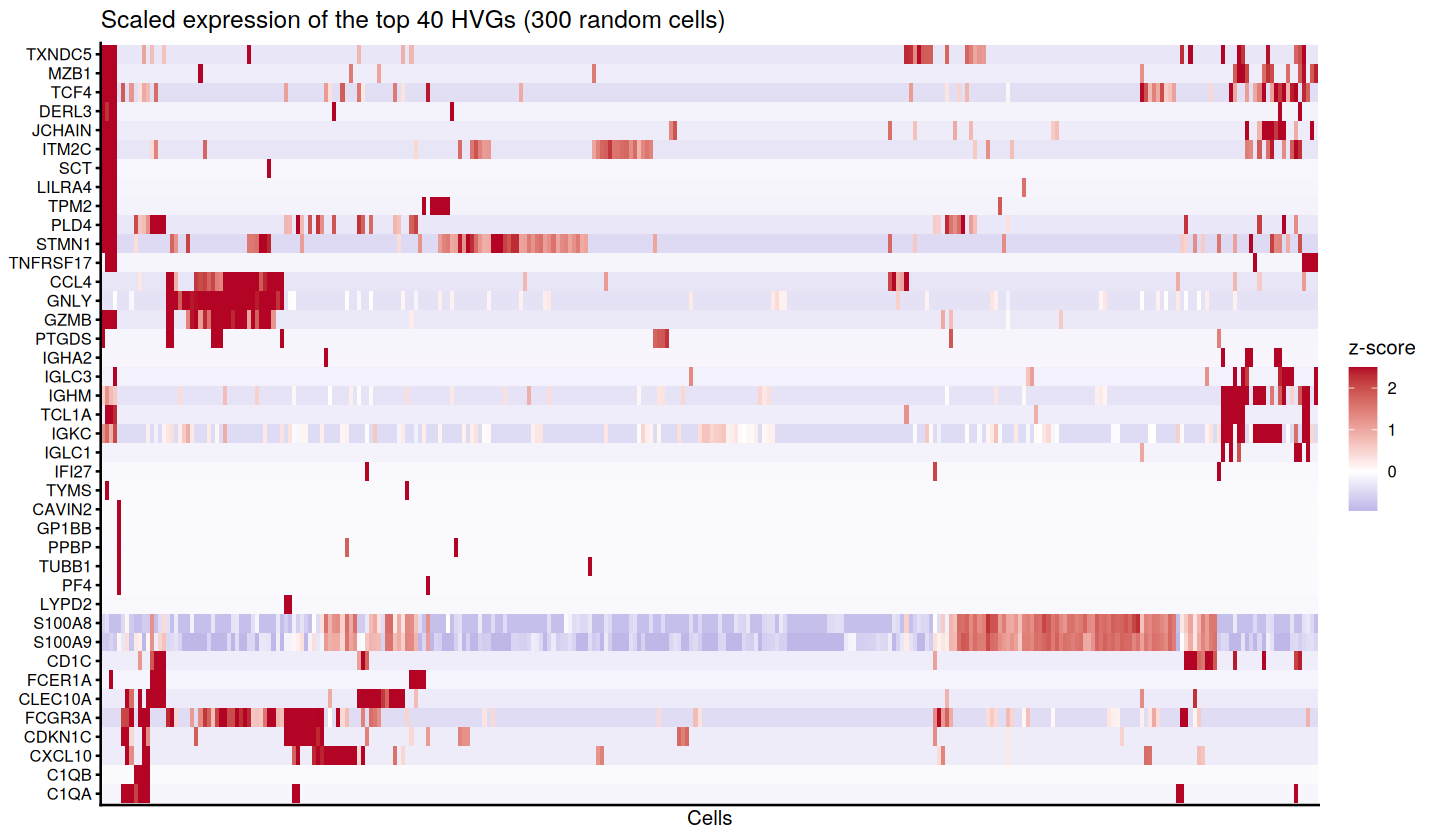

In [42]:
set.seed(seed)
hm_cells <- sample(colnames(scaled), min(300, ncol(scaled)))
hm <- scaled[head(hvg_genes, 40), hm_cells]
hm <- hm[hclust(dist(hm))$order, hclust(dist(t(hm)))$order]
hm_long <- as.data.frame(as.table(pmax(pmin(hm, 2.5), -2.5)))      # clip to +-2.5 for display contrast
colnames(hm_long) <- c("gene", "cell", "z")

options(repr.plot.width = 12, repr.plot.height = 7)
p <- ggplot(hm_long, aes(x = cell, y = gene, fill = z)) +
  geom_raster() +
  scale_fill_gradient2(low = "#3B4CC0", mid = "white", high = "#B40426", midpoint = 0) +
  labs(title = "Scaled expression of the top 40 HVGs (300 random cells)", x = "Cells", y = NULL, fill = "z-score") +
  theme(axis.text.x = element_blank(), axis.ticks.x = element_blank())
save_plot(p, "18_scaled_heatmap.png", width = 12, height = 7)

### Regressing out unwanted variation (use with care)

`ScaleData(vars.to.regress = ...)` fits, for every gene, a linear model of expression on covariates such as `percent.mt` or `nCount_RNA`, and scales the **residuals** instead. This removes that covariate's linear effect.

It is tempting but risky:

* If the covariate is correlated with biology, regressing it out **removes biology**. For example, mitochondrial content differs between cell types, and cell-cycle genes define proliferating populations.
* It only removes linear effects, and it inflates computation.
* Current guidance is to regress only when a covariate demonstrably drives unwanted structure, and to compare results with and without it (Luecken & Theis, 2019).

The cell below demonstrates the effect on a copy of the data. **The main object is not changed.**

scaled scaled + percent.mt regressed 
                 0.0342666133                  0.0001242306

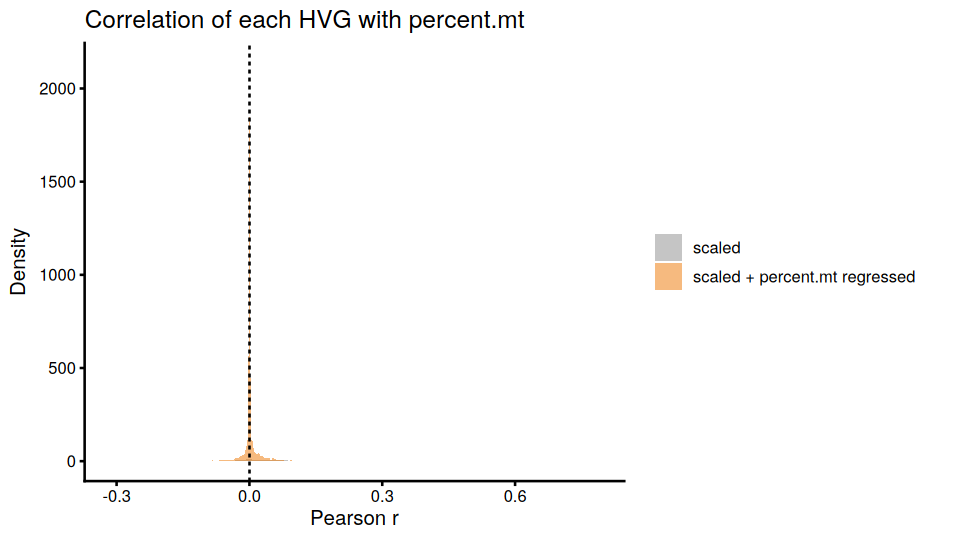

In [43]:
pbmc_reg <- ScaleData(subset(pbmc, features = hvg_genes), features = hvg_genes,
                      vars.to.regress = "percent.mt", verbose = FALSE)

mt <- pbmc@meta.data$percent.mt
cor_mt <- data.frame(
  stage = factor(rep(c("scaled", "scaled + percent.mt regressed"), each = length(hvg_genes)),
                 levels = c("scaled", "scaled + percent.mt regressed")),
  r = c(apply(scaled, 1, cor, y = mt),
        apply(LayerData(pbmc_reg, assay = "RNA", layer = "scale.data"), 1, cor, y = mt))
)
rm(pbmc_reg)
tapply(abs(cor_mt$r), cor_mt$stage, median)

options(repr.plot.width = 8, repr.plot.height = 4.5)
p <- ggplot(cor_mt, aes(x = r, fill = stage)) +
  geom_density(alpha = 0.5, colour = NA) + geom_vline(xintercept = 0, linetype = "dashed") +
  scale_fill_manual(values = c(scaled = "grey55", `scaled + percent.mt regressed` = "darkorange2")) +
  labs(title = "Correlation of each HVG with percent.mt", x = "Pearson r", y = "Density", fill = NULL)
save_plot(p, "19_regression_percent_mt.png", width = 8, height = 4.5)

> **Discussion**
> 1. After regression the correlation with `percent.mt` is close to zero for every gene. Is that good or bad if mitochondrial content truly differs between monocytes and lymphocytes?
> 2. When might you prefer **not** to scale genes to unit variance?
> 3. Why is scaling done only on the HVGs?

## 10. Save, summary and runtime

The saved object contains raw counts (`counts`, not corrected for ambient RNA; see Section 2), log-normalized data (`data`), scaled HVGs (`scale.data`), the HVG list and all QC metadata, including the doublet scores. It is the input for dimensionality reduction and clustering in the next session.

In [44]:
mark_stage("10. Save")

pbmc$keep <- NULL     # every remaining cell was kept; the column is no longer informative
saveRDS(pbmc, file = rds_file)
write.csv(pbmc@meta.data, file.path(table_dir, "cell_metadata.csv"))

qc_log
pbmc

step,cells,genes
<chr>,<dbl>,<dbl>
1. Cell Ranger filtered barcodes,10985,36601
2. Pass QC thresholds (MAD),9885,36601
3. ... and called singlet,8713,36601
4. Genes detected in >= 3 cells,8713,22180


An object of class Seurat 
22180 features across 8713 samples within 1 assay 
Active assay: RNA (22180 features, 2000 variable features)
 3 layers present: counts, data, scale.data

### Runtime per stage

How long each stage took in this run, from the `mark_stage()` calls at the start of every stage (defined in the setup cell). The table is also written to `data/tables/pbmc10k_stage1/runtime_per_stage.csv`.

* **Elapsed** = wall-clock time from the start of one stage to the start of the next. It is only meaningful when the notebook runs top to bottom without pauses (Run All, or `jupyter nbconvert --execute`); when cells are run by hand it also counts the time spent reading.
* **CPU** = processor time used by R in that stage. It ignores idle time, and can exceed the elapsed time if the BLAS library uses several threads.

stage,elapsed_seconds,cpu_seconds,elapsed_minutes,percent_of_total
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
0. Setup,0.1,0.1,0.00,0.0
1. Load the count matrix,65.6,62.6,1.09,25.2
2. Ambient RNA check (SoupX),3.9,9.4,0.06,1.5
3. Doublets (scDblFinder),66.1,117.4,1.10,25.4
4. QC metrics,14.1,13.4,0.23,5.4
5. Filtering thresholds,2.6,2.5,0.04,1.0
6. Apply filters,4.6,4.5,0.08,1.8
7. Normalization,13.2,13.0,0.22,5.1
8. Highly variable genes,9.3,8.9,0.16,3.6


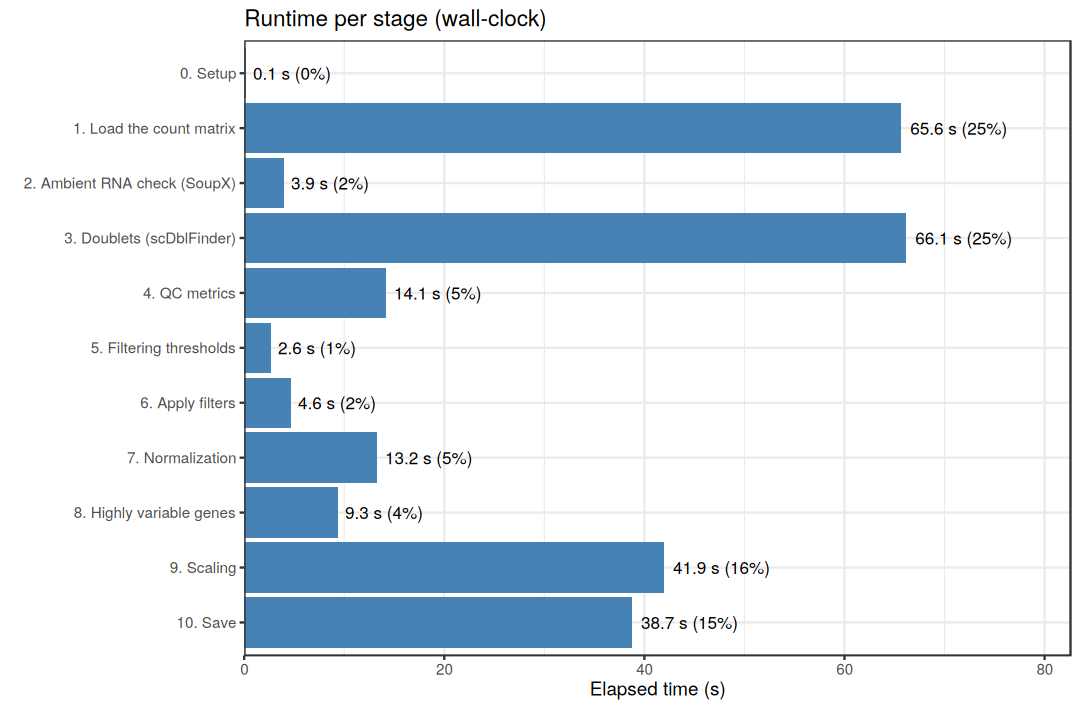

In [45]:
mark_stage("End")
marks <- data.frame(stage = names(stage_marks),
                    time  = vapply(stage_marks, `[[`, numeric(1), "time"),
                    cpu   = vapply(stage_marks, `[[`, numeric(1), "cpu"),
                    row.names = NULL)
marks <- marks[order(marks$time), ]          # a stage that was re-run counts from its latest start

runtimes <- data.frame(
  stage           = head(marks$stage, -1),
  elapsed_seconds = round(diff(marks$time), 1),
  cpu_seconds     = round(diff(marks$cpu), 1)
)
runtimes$elapsed_minutes  <- round(runtimes$elapsed_seconds / 60, 2)
runtimes$percent_of_total <- round(100 * runtimes$elapsed_seconds / sum(runtimes$elapsed_seconds), 1)
write.csv(runtimes, file.path(table_dir, "runtime_per_stage.csv"), row.names = FALSE)

rbind(runtimes,
      data.frame(stage = "Total", elapsed_seconds = sum(runtimes$elapsed_seconds), cpu_seconds = sum(runtimes$cpu_seconds),
                 elapsed_minutes = round(sum(runtimes$elapsed_seconds) / 60, 2), percent_of_total = 100))

runtimes$stage <- factor(runtimes$stage, levels = rev(runtimes$stage))   # first stage at the top
options(repr.plot.width = 9, repr.plot.height = 1.5 + 0.4 * nrow(runtimes))
p <- ggplot(runtimes, aes(x = elapsed_seconds, y = stage)) +
  geom_col(fill = "steelblue") +
  geom_text(aes(label = sprintf("%.1f s (%.0f%%)", elapsed_seconds, percent_of_total)), hjust = -0.1, size = 3.5) +
  scale_x_continuous(expand = expansion(mult = c(0, 0.25))) +
  labs(title = "Runtime per stage (wall-clock)", x = "Elapsed time (s)", y = NULL) +
  theme_bw()
save_plot(p, "20_runtime_per_stage.png", width = 9, height = 1.5 + 0.4 * nrow(runtimes))

### Key take-aways

1. **Ambient RNA contaminates every cell.** SoupX estimates the contamination fraction from genes that cannot be expressed in most cells and subtracts the soup; empty droplets give the best soup estimate. This tutorial only estimates it; a full analysis should correct it (`load10X` → `autoEstCont` → `adjustCounts`, Section 2).
2. **QC metrics are diagnostic, not absolute.** Low counts, high mitochondrial fraction and extreme counts each point to a specific failure mode, but each can also be biology.
3. **Data-driven (MAD) thresholds** adapt to the dataset. Filter permissively and revisit after clustering.
4. **Doublets** are expected (~0.8% per 1,000 cells). Only heterotypic doublets can be found from expression. Run detection before stringent filtering (on ambient-corrected counts in a full analysis).
5. **Normalization** removes library-size effects. The log transform makes effects multiplicative-to-additive and tames the mean–variance relationship.
6. **HVG selection** keeps genes whose variance exceeds technical expectation. It concentrates biological signal for PCA.
7. **Scaling** gives every HVG equal weight in PCA. Regressing out covariates is powerful but can remove real biology.

### References

* Ahlmann-Eltze C, Huber W (2023). Comparison of transformations for single-cell RNA-seq data. *Nature Methods* 20:665–672.
* Choudhary S, Satija R (2022). Comparison and evaluation of statistical error models for scRNA-seq. *Genome Biology* 23:27.
* Germain P-L, Lun A, Garcia Meixide C, Macnair W, Robinson MD (2021). Doublet identification in single-cell sequencing data using *scDblFinder*. *F1000Research* 10:979.
* Hafemeister C, Satija R (2019). Normalization and variance stabilization of single-cell RNA-seq data using regularized negative binomial regression. *Genome Biology* 20:296.
* Hao Y *et al.* (2024). Dictionary learning for integrative, multimodal and scalable single-cell analysis (Seurat v5). *Nature Biotechnology* 42:293–304.
* Heumos L *et al.* (2023). Best practices for single-cell analysis across modalities. *Nature Reviews Genetics* 24:550–572.
* Ilicic T *et al.* (2016). Classification of low quality cells from single-cell RNA-seq data. *Genome Biology* 17:29.
* Lause J, Berens P, Kobak D (2021). Analytic Pearson residuals for normalization of single-cell RNA-seq UMI data. *Genome Biology* 22:258.
* Luecken MD, Theis FJ (2019). Current best practices in single-cell RNA-seq analysis: a tutorial. *Molecular Systems Biology* 15:e8746.
* Lun ATL (2018). Overcoming systematic errors caused by log-transformation of normalized single-cell RNA sequencing data. *bioRxiv* 404962.
* Lun ATL, Bach K, Marioni JC (2016). Pooling across cells to normalize single-cell RNA sequencing data with many zero counts. *Genome Biology* 17:75.
* Lun ATL, McCarthy DJ, Marioni JC (2016). A step-by-step workflow for low-level analysis of single-cell RNA-seq data with Bioconductor. *F1000Research* 5:2122.
* McCarthy DJ, Campbell KR, Lun ATL, Wills QF (2017). Scater: pre-processing, quality control, normalization and visualization of single-cell RNA-seq data in R. *Bioinformatics* 33:1179–1186.
* McGinnis CS, Murrow LM, Gartner ZJ (2019). DoubletFinder: doublet detection in single-cell RNA sequencing data using artificial nearest neighbors. *Cell Systems* 8:329–337.
* Osorio D, Cai JJ (2021). Systematic determination of the mitochondrial proportion in human and mice tissues for single-cell RNA-sequencing data quality control. *Bioinformatics* 37:963–967.
* Stoeckius M *et al.* (2018). Cell Hashing with barcoded antibodies enables multiplexing and doublet detection for single cell genomics. *Genome Biology* 19:224.
* Stuart T *et al.* (2019). Comprehensive integration of single-cell data. *Cell* 177:1888–1902.
* Svensson V (2020). Droplet scRNA-seq is not zero-inflated. *Nature Biotechnology* 38:147–150.
* Wolock SL, Lopez R, Klein AM (2019). Scrublet: computational identification of cell doublets in single-cell transcriptomic data. *Cell Systems* 8:281–291.
* Xi NM, Li JJ (2021). Benchmarking computational doublet-detection methods for single-cell RNA sequencing data. *Cell Systems* 12:176–194.
* Young MD, Behjati S (2020). SoupX removes ambient RNA contamination from droplet-based single-cell RNA sequencing data. *GigaScience* 9:giaa151.

In [46]:
sessionInfo()

R version 4.4.3 (2025-02-28)
Platform: x86_64-conda-linux-gnu
Running under: Ubuntu 22.04.5 LTS

Matrix products: default
BLAS/LAPACK: /home/sreeram/miniconda3/envs/seurat_env/lib/libopenblasp-r0.3.34.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

time zone: Asia/Calcutta
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] patchwork_1.3.2    ggplot2_4.0.3      tidyr_1.3.2        dplyr_1.2.1       
[5] Matrix_1.7-6       Seurat_5.5.1       SeuratObject_5.4.0 sp_2.2-3          

loaded via a namespace (and not attached):
  [1] RcppAnnoy_0.0.23            splines_4.4.3              
  [3] later_1.4.8   